# Session 1 (Handwriting): all channels, segment 1 vs segment 2

The recording was paused once for an impedance check, so it has **two segments**, treated
here as two separate tasks. Each segment is loaded and filtered **on its own** so the jump
at the break doesn't leak into the filtered signal.

All 24 channels, ordered front to back (frontal Fp/F, temporal T, central C, parietal P,
occipital O), sampled at 500 Hz, every sample plotted.
Segment 1 is on the left and segment 2 on the right.

1. Original (unfiltered) data
2. Alpha band, 8–13 Hz (high-pass 8 Hz + low-pass 13 Hz)
3. Gamma band, 30–100 Hz (high-pass 30 Hz + low-pass 100 Hz), with a 60 Hz notch for US mains noise
4. Between alpha and gamma, 13–30 Hz (beta band): alpha and gamma removed
5. Theta band, 4–8 Hz
6. ERP / P300 (needs stimulus event markers)
7. Frequency decomposition (FFT): does theta rise from segment 1 (easy) to segment 2 (difficult)?
8. Cleaned analysis: ICA (eye/muscle removal) + theta/alpha measured above the 1/f background

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make the repo root importable when running from notebooks/
REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "processing").is_dir():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from processing import load_session

SESSION_DIR = REPO_ROOT / "data" / "Session 1_ Handwriting"

In [2]:
session = load_session(SESSION_DIR)
assert session.sfreq == 500, session.sfreq

CHANNELS = session.ch_names  # all 24, front to back
segments = session.segments

for i, (info, seg) in enumerate(zip(session.segment_info, segments), start=1):
    print(f"Segment {i}: {seg.n_times} samples = {seg.times[-1]:.2f} s, started {info.start_time} UTC")
print("Channels:", ", ".join(CHANNELS))

Segment 1: 74584 samples = 149.17 s, started 2026-11-07 19:54:41.517353 UTC
Segment 2: 101792 samples = 203.58 s, started 2026-11-07 19:57:57 UTC
Channels: Fp1, Fp2, F9, F7, F3, Fz, F4, F8, F10, T9, T7, C3, C4, T8, T10, P9, P7, P3, Pz, P4, P8, P10, O1, O2


In [3]:
def plot_segments(segs, title, sharey_rows=True):
    """Grid of channels (rows) x segments (columns), every sample plotted, in µV."""
    n_rows = len(CHANNELS)
    fig, axes = plt.subplots(
        n_rows, 2, figsize=(18, 1.6 * n_rows), sharex="col",
        sharey="row" if sharey_rows else False, squeeze=False,
    )
    for col, seg in enumerate(segs):
        data = seg.get_data(picks=CHANNELS) * 1e6  # V -> µV
        t = seg.times
        for row, ch in enumerate(CHANNELS):
            ax = axes[row, col]
            ax.plot(t, data[row], lw=0.3, color="C0", rasterized=True)
            ax.set_ylabel(f"{ch}\n(µV)", rotation=0, ha="right", va="center")
            ax.margins(x=0)
            ax.grid(alpha=0.3)
        axes[0, col].set_title(f"Segment {col + 1}  ({seg.times[-1]:.1f} s, {seg.n_times} samples)")
        axes[-1, col].set_xlabel("Time from segment start (s)")
    fig.suptitle(title, fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.99))
    plt.show()

## 1. Original data

The raw eego signal sits on large, slowly drifting offsets (mV range), so each panel gets
its own y-axis here.

**Why this plot:** check signal quality before any processing: drift, noisy channels, and artifacts (blinks, movement) that filtering could hide or smear.

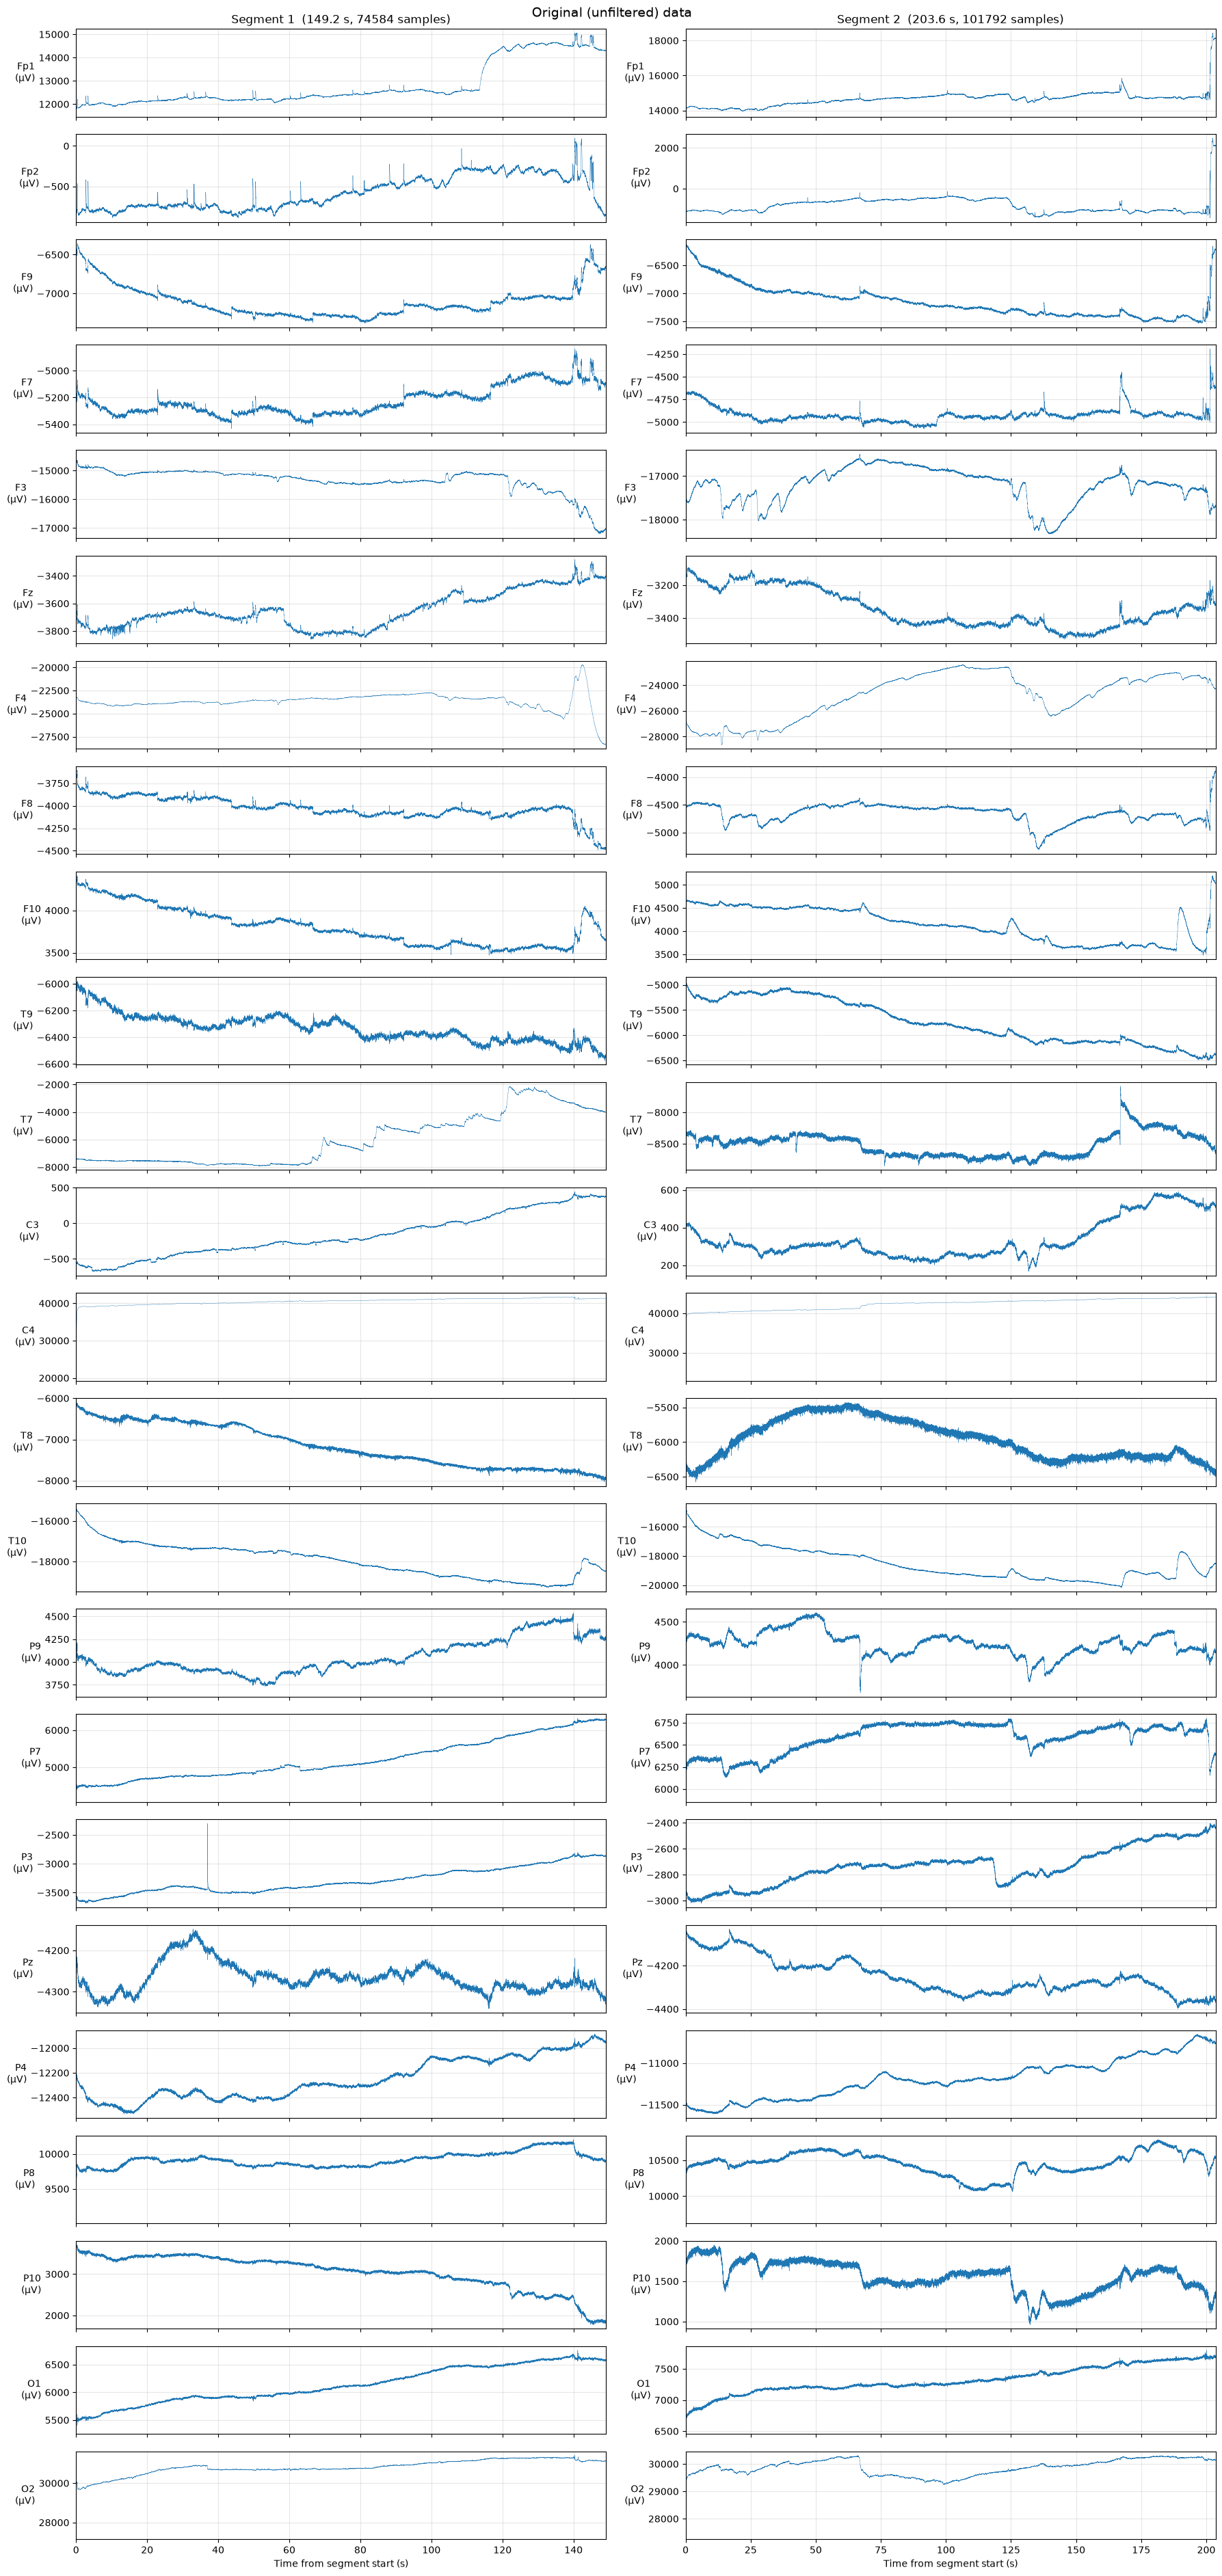

In [4]:
plot_segments(segments, "Original (unfiltered) data", sharey_rows=False)

## 2. Alpha band (8–13 Hz)

A band-pass is a high-pass at 8 Hz combined with a low-pass at 13 Hz; MNE's
`filter(l_freq=8, h_freq=13)` applies both (zero-phase FIR). The two segments share a
y-axis per channel so their amplitudes can be compared.

**Why this plot:** alpha weakens when the brain is engaged with a task, so comparing it between segments shows which task demanded more attention.

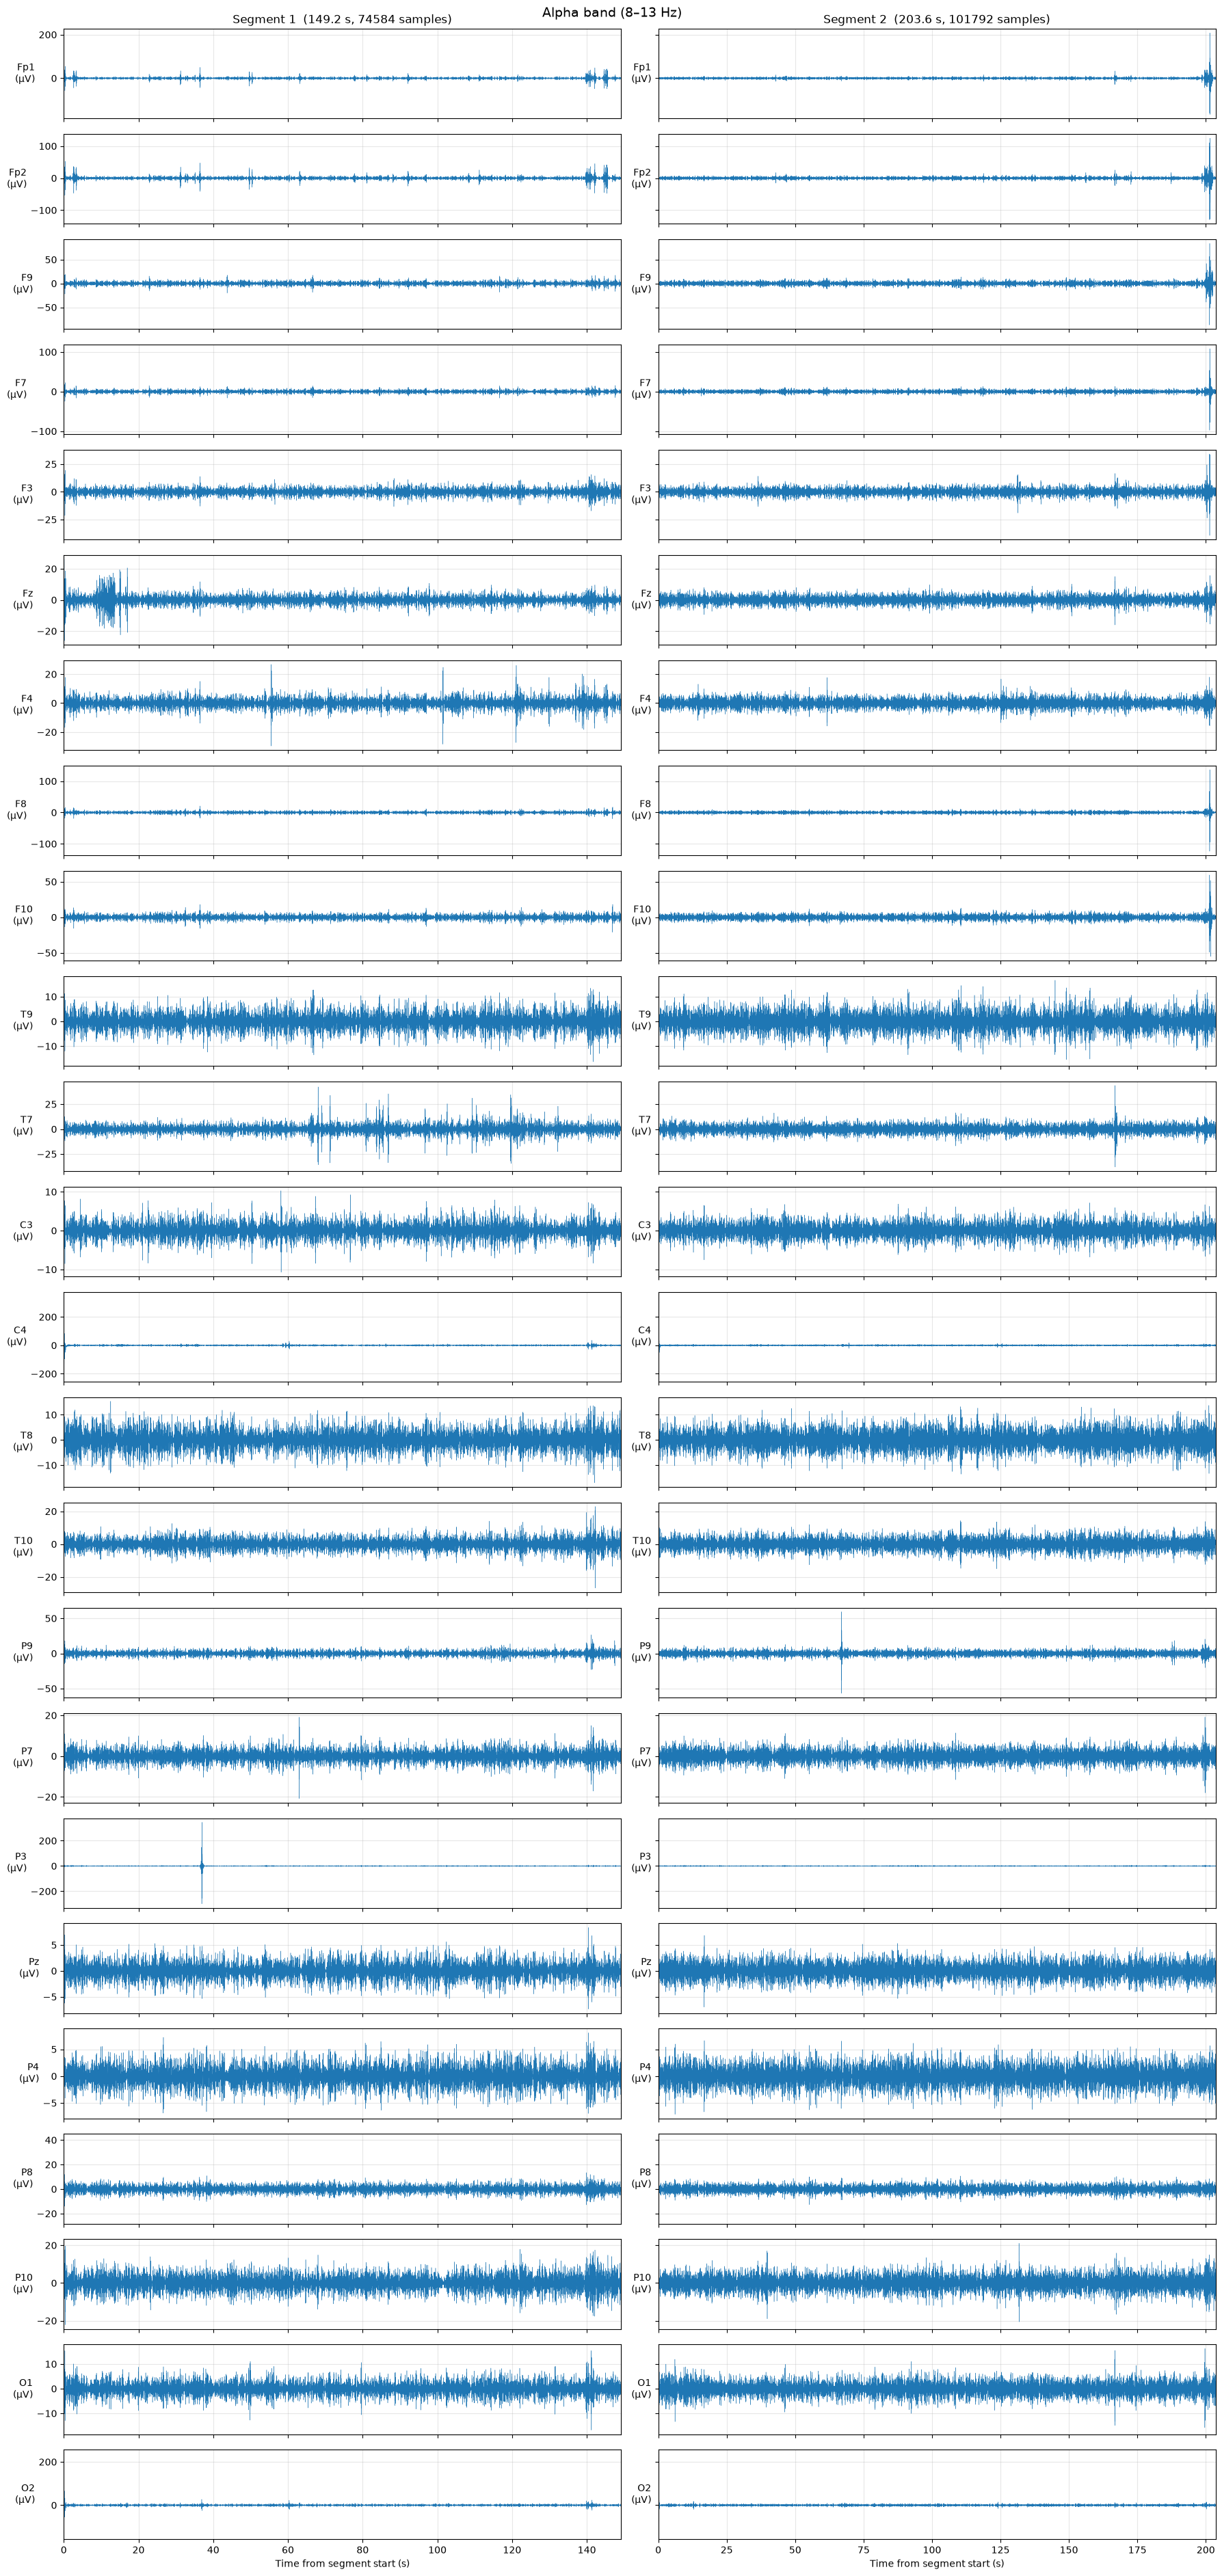

In [5]:
alpha = [seg.copy().filter(l_freq=8.0, h_freq=13.0, verbose="error") for seg in segments]
plot_segments(alpha, "Alpha band (8–13 Hz)")

## 3. Gamma band (30–100 Hz)

High-pass 30 Hz + low-pass 100 Hz. The 60 Hz mains frequency (US) falls inside this band
and would otherwise dominate it, so it is notched out first. Gamma overlaps strongly with muscle (EMG) activity: forehead tension and eye movements
(Fp/F channels), jaw clenching (temporal T channels). Even resting scalp EEG is heavily
contaminated by muscle activity at these frequencies, so **gamma is not used as a measure of
mental effort here**. It's shown as an indicator of muscle artifact.

**Why this plot:** gamma on the scalp is mostly muscle activity, so it shows how much muscle tension (forehead, jaw, eyes) each task produced, which is a confound to watch rather than a measure of effort.

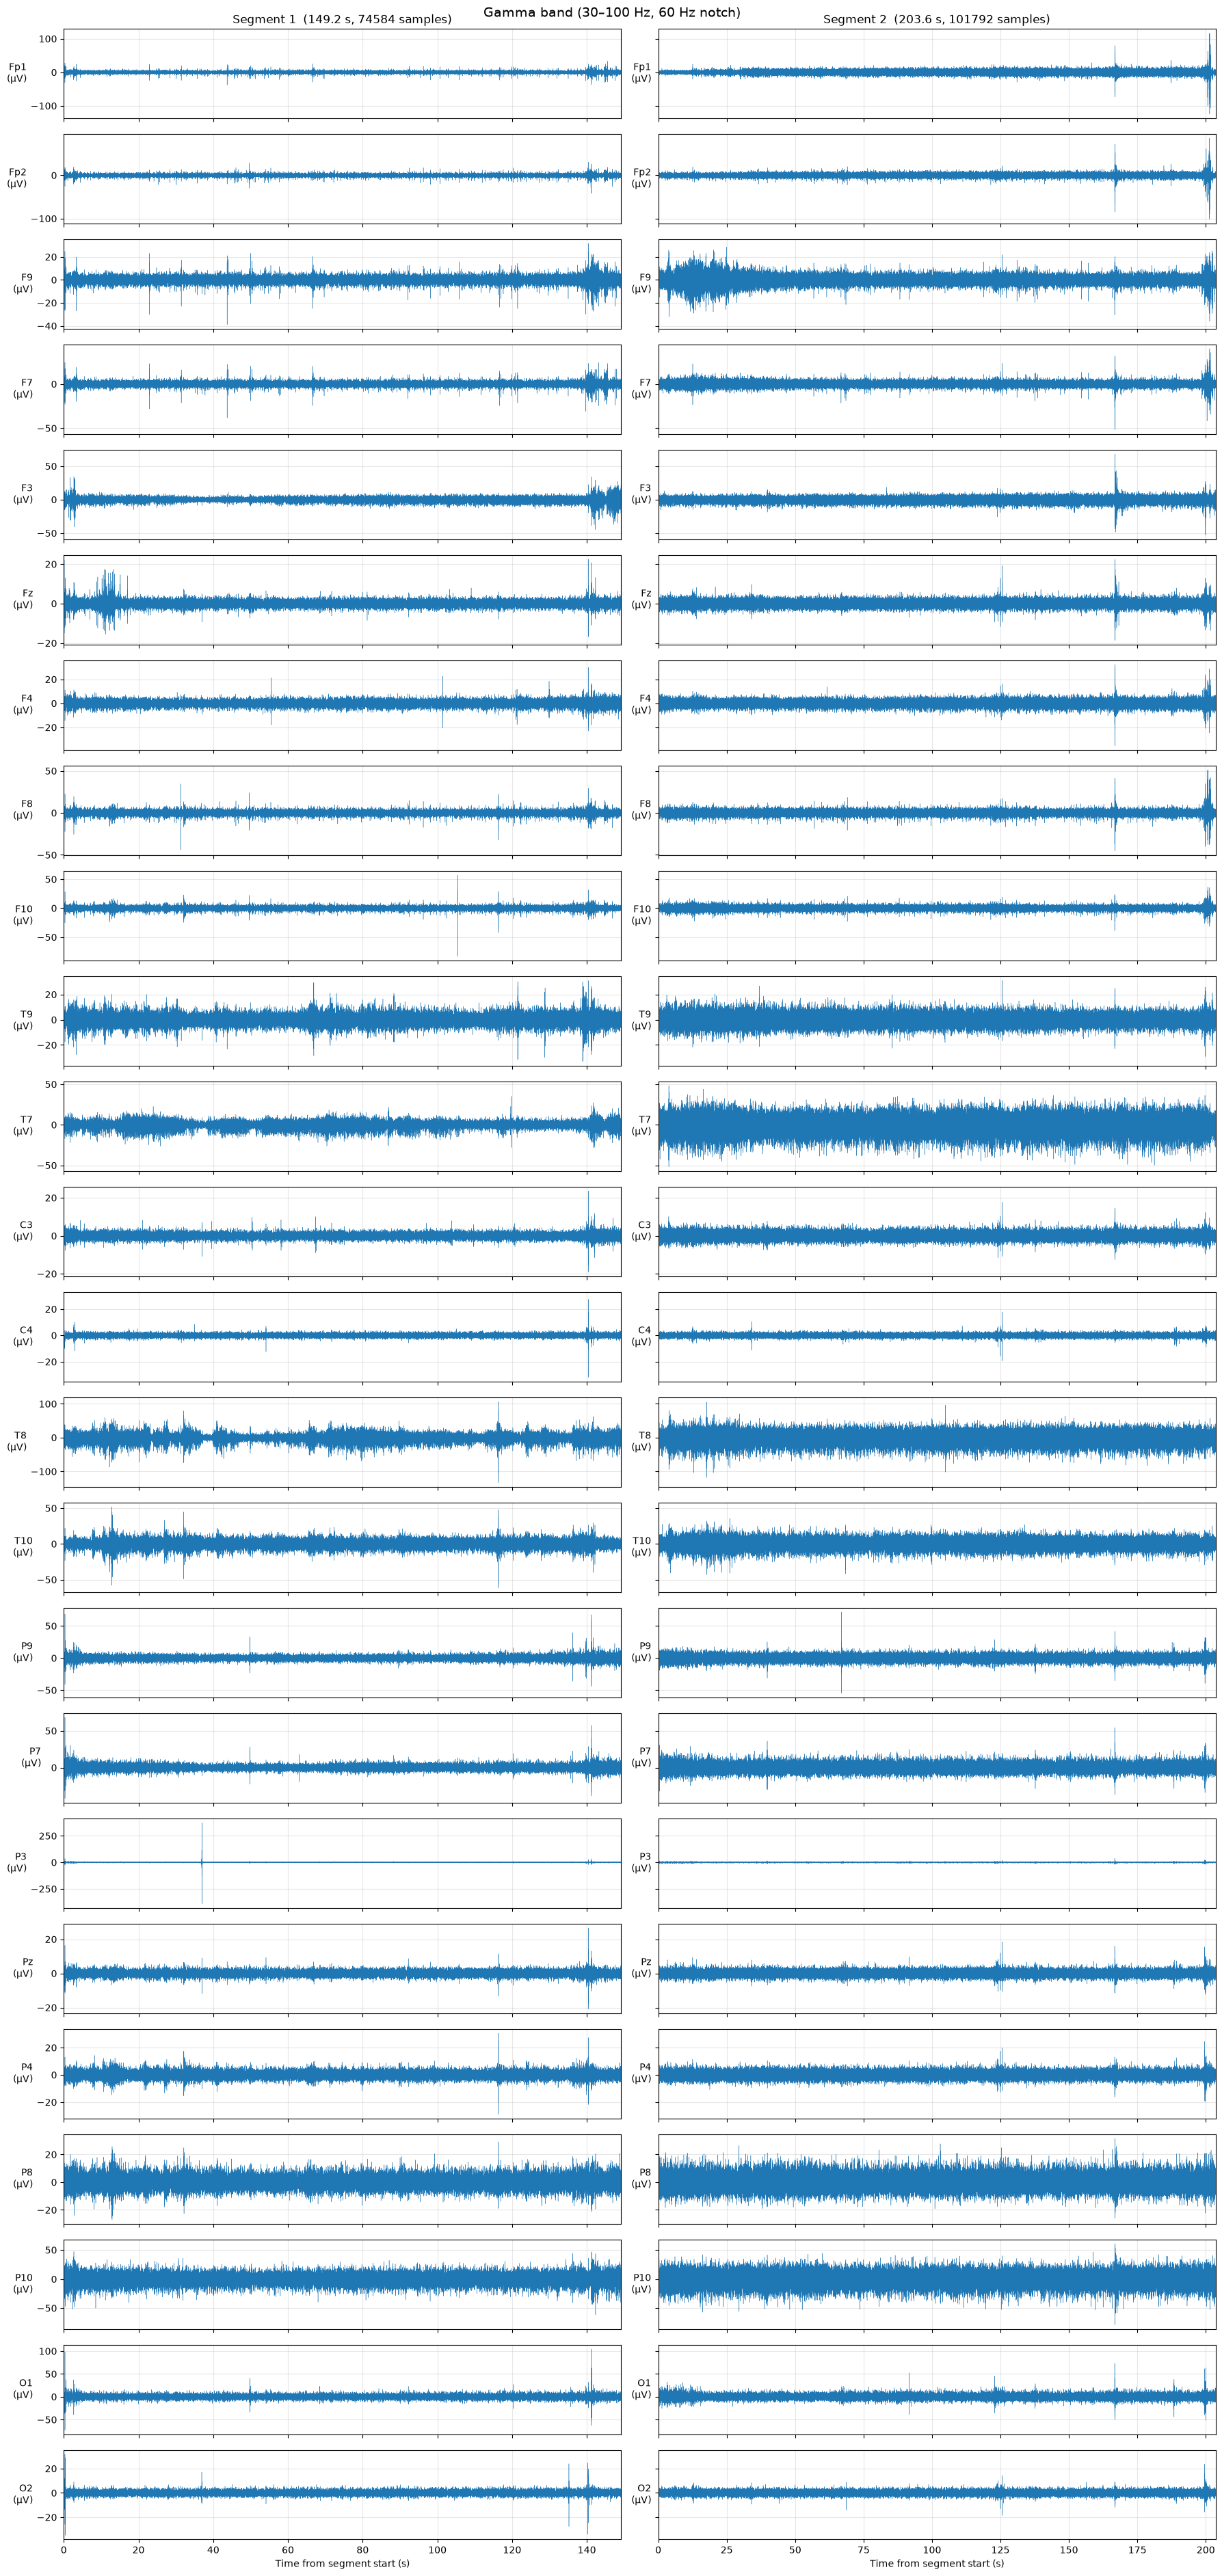

In [6]:
gamma = [
    seg.copy()
    .notch_filter(freqs=60.0, verbose="error")
    .filter(l_freq=30.0, h_freq=100.0, verbose="error")
    for seg in segments
]
plot_segments(gamma, "Gamma band (30–100 Hz, 60 Hz notch)")

## 4. Between alpha and gamma: 13–30 Hz (beta band)

Removes the alpha band and everything below it with a 13 Hz high-pass, and the gamma band
and everything above it with a 30 Hz low-pass, so only 13–30 Hz remains. This range is the
**beta** band. **It is not used as a measure of mental effort here:** over the motor
cortex (C3/C4) beta drops whenever you move, which reflects the movement itself, and muscle
activity (EMG) often has spectral peaks in the beta range that look like real EEG beta.
Both get worse in a harder motor task, so a beta difference can't be read as effort.

**Why this plot:** beta mostly tracks movement and muscle activity in these tasks, so it shows how differently the two tasks were performed physically, which is a confound to watch rather than a measure of effort.

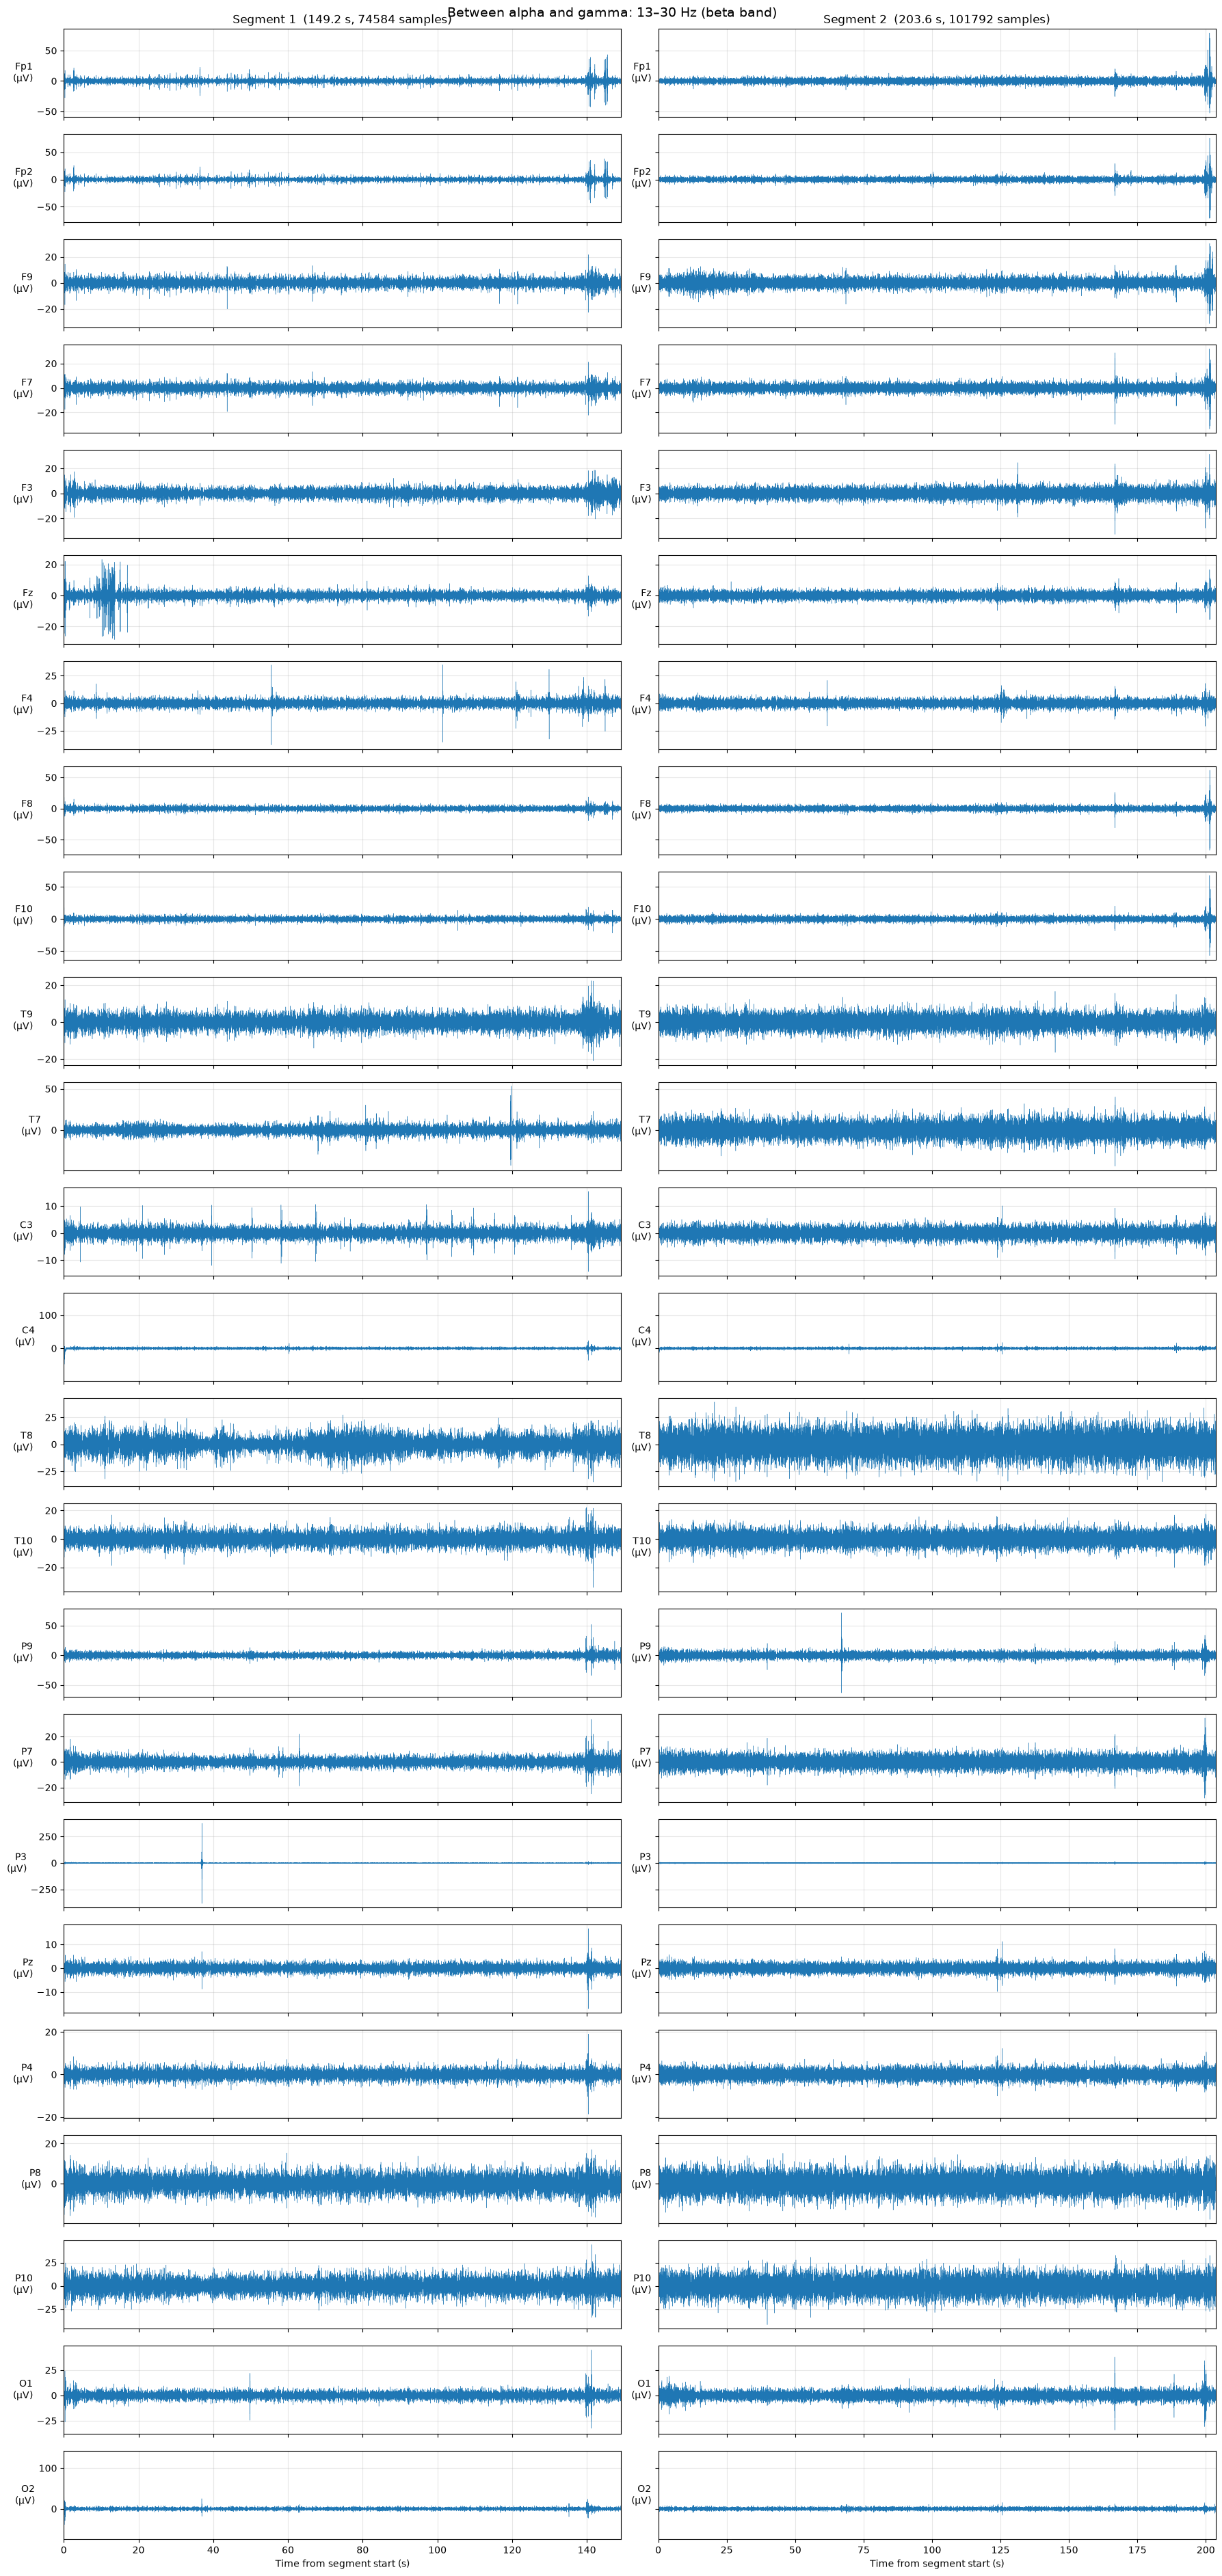

In [7]:
beta = [seg.copy().filter(l_freq=13.0, h_freq=30.0, verbose="error") for seg in segments]
plot_segments(beta, "Between alpha and gamma: 13–30 Hz (beta band)")

## 5. Theta band (4–8 Hz)

High-pass 4 Hz + low-pass 8 Hz. Theta related to mental workload is strongest over the frontal cortex (especially Fz).

**Why this plot:** frontal theta rises with task difficulty, working memory load and executive control, so higher theta in one segment suggests that task was more demanding.

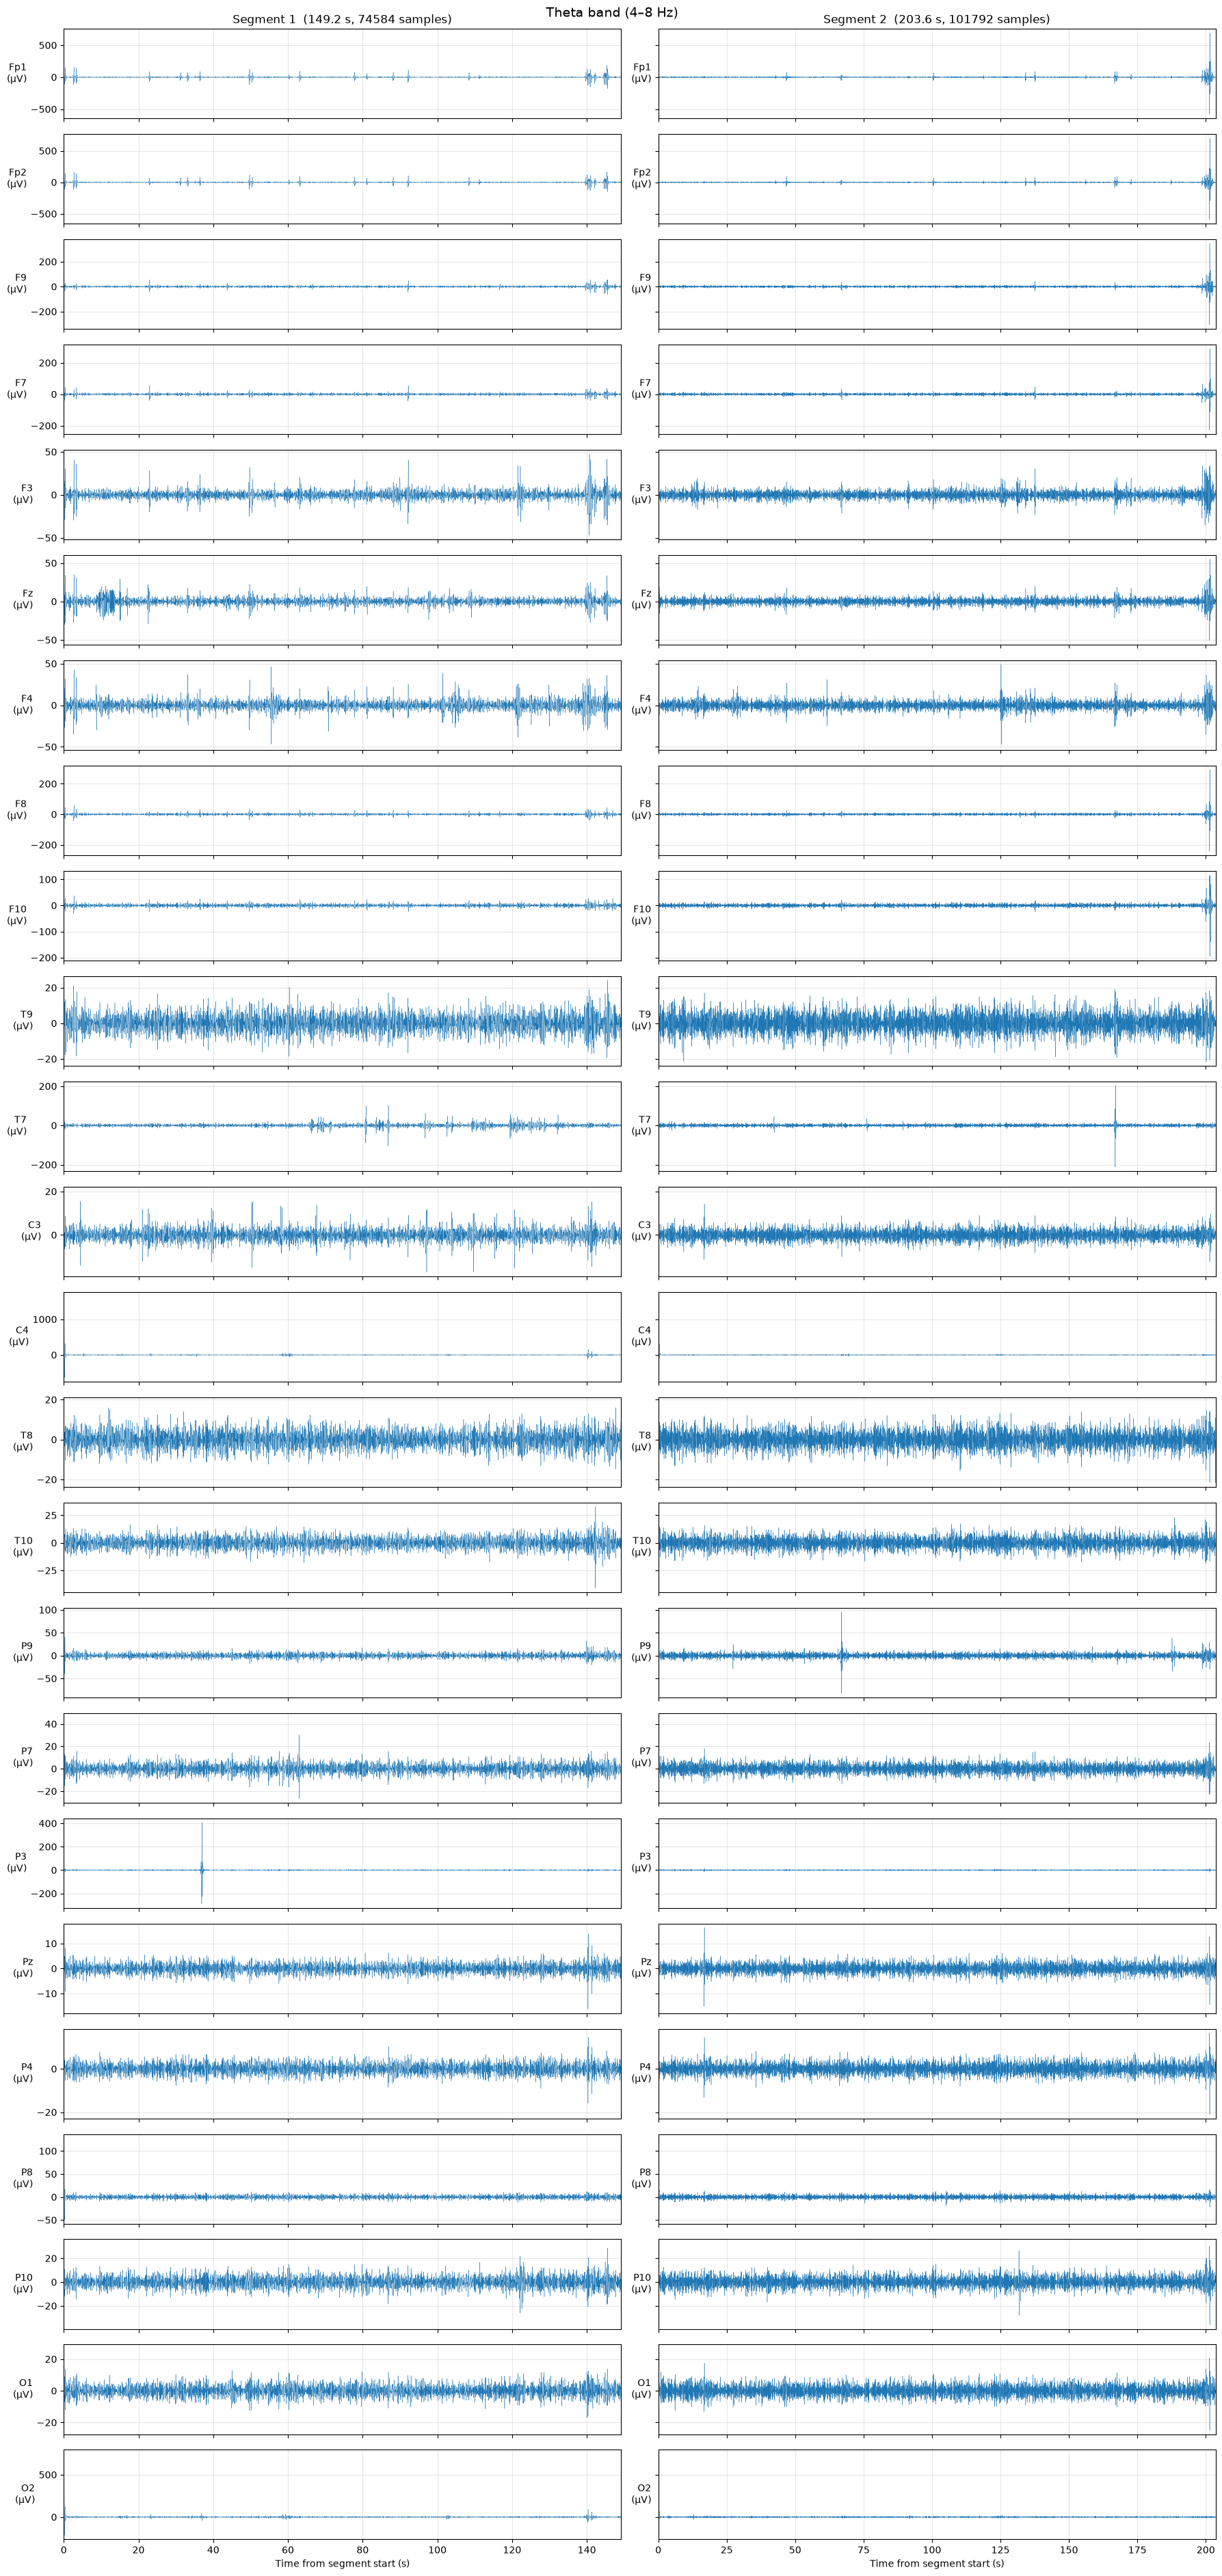

In [8]:
theta = [seg.copy().filter(l_freq=4.0, h_freq=8.0, verbose="error") for seg in segments]
plot_segments(theta, "Theta band (4–8 Hz)")

## 6. Event-related potential (ERP) and P300

An ERP is the average EEG response time-locked to a repeated stimulus: cut a window around
every stimulus marker, then average the windows so random background EEG cancels out and
the brain's consistent response remains. The **P300** is a positive peak roughly
250–500 ms after the stimulus, largest over the parietal midline. This montage has no Cz,
so it is measured at **Pz** (with P3, P4 and Fz for comparison).

**This needs many stimulus markers in the recording** (a few dozen trials at least), e.g.
one marker per presented letter or cue. Session 1 has only one marker per segment, so the
cell below reports that instead of plotting a single trial, which would be noise.

**Why this plot:** P300 amplitude shrinks as working memory and attention are used up by a primary task, so a smaller P300 in one segment would suggest that task was more demanding.

In [9]:
import mne

ERP_CHANNELS = ["Fz", "P3", "Pz", "P4"]
P300_WINDOW = (0.25, 0.50)  # seconds after the stimulus
MIN_TRIALS = 20             # fewer trials than this gives an ERP dominated by noise


def make_epochs(seg, tmin=-0.2, tmax=0.8):
    """Cut epochs around every stimulus marker (all annotations except impedance checks)."""
    filtered = seg.copy().filter(l_freq=0.1, h_freq=30.0, verbose="error")  # standard ERP band
    events, event_id = mne.events_from_annotations(filtered, regexp=r"^(?!impedance)", verbose="error")
    if len(events) < MIN_TRIALS:
        return None, len(events)
    epochs = mne.Epochs(
        filtered, events, event_id, tmin=tmin, tmax=tmax, picks=ERP_CHANNELS,
        baseline=(None, 0), reject=dict(eeg=100e-6),  # drop trials with >100 µV artifacts
        preload=True, verbose="error",
    )
    return epochs, len(events)


def plot_erps(raw_segments):
    results = [make_epochs(seg) for seg in raw_segments]
    for i, (epochs, n) in enumerate(results, start=1):
        if epochs is None:
            print(f"Segment {i}: {n} stimulus marker(s), need at least {MIN_TRIALS} for an ERP. Skipped.")
    if all(ep is None for ep, _ in results):
        return

    fig, axes = plt.subplots(len(ERP_CHANNELS), 2, figsize=(14, 2.6 * len(ERP_CHANNELS)),
                             sharex=True, sharey="row", squeeze=False)
    for col, (epochs, _) in enumerate(results):
        axes[0, col].set_title(f"Segment {col + 1}" + ("" if epochs is None else f"  ({len(epochs)} trials)"))
        if epochs is None:
            continue
        evoked = epochs.average()
        t = evoked.times * 1000
        for row, ch in enumerate(ERP_CHANNELS):
            ax = axes[row, col]
            y = evoked.get_data(picks=ch)[0] * 1e6
            ax.axvspan(*(np.array(P300_WINDOW) * 1000), color="C1", alpha=0.15, label="P300 window")
            ax.axvline(0, color="k", lw=0.8)
            ax.axhline(0, color="k", lw=0.5)
            ax.plot(t, y, color="C0")
            in_win = (evoked.times >= P300_WINDOW[0]) & (evoked.times <= P300_WINDOW[1])
            k = np.argmax(y[in_win])
            ax.plot(t[in_win][k], y[in_win][k], "o", color="C3")
            ax.annotate(f"{y[in_win][k]:.1f} µV @ {t[in_win][k]:.0f} ms", (t[in_win][k], y[in_win][k]),
                        textcoords="offset points", xytext=(6, 6), fontsize=8)
            ax.set_ylabel(f"{ch}\n(µV)", rotation=0, ha="right", va="center")
            ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set_xlabel("Time from stimulus (ms)")
    axes[0, 0].legend(loc="upper left", fontsize=8)
    fig.suptitle("ERP (0.1–30 Hz) with P300 peak", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


# Uses all 24 channels (session.segments), not just the frontal ones
plot_erps(session.segments)

Segment 1: 1 stimulus marker(s), need at least 20 for an ERP. Skipped.
Segment 2: 1 stimulus marker(s), need at least 20 for an ERP. Skipped.


## 7. Frequency decomposition (FFT)

**Question:** segment 1 was the easy task and segment 2 the difficult one. If segment 2 put
more load on working memory, theta power at **Fz** (the front of the head, on the midline)
should be **higher in segment 2**, and alpha over the parietal channels (P, at the back of the
head) should be **lower** ([Gevins et al., 1997](https://pubmed.ncbi.nlm.nih.gov/9177767/);
[Gevins et al., 1998](https://api.crossref.org/works/10.1518%2F001872098779480578)).

**Method:** Welch's method, as recommended in the
[Neurosity FFT primer](https://neurosity.co/guides/fast-fourier-transform-fft-eeg-analysis-primer).
Each segment is cut into 2 s windows overlapping by 50%. Each window gets a Hann window and
an FFT, and the spectra are averaged. 2 s windows give 0.5 Hz detail, which is enough to
resolve the 4 Hz-wide theta band.

**Cleaning before the FFT** (more than the primer suggests, because this data needs it):
- **1 Hz high-pass:** the raw signal sits on drifting offsets of several mV, which would
  leak into the theta and delta frequencies.
- **60 Hz notch:** removes US mains power noise.
- **Excluded channels:** P3, C4 and O2, which had large electrode pops in the plots above.
- **Per-channel window rejection:** a channel's window is dropped if it swings more than
  150 µV (blinks, movement). This is done per channel, because T7/T8 are noisy throughout
  and would otherwise throw away clean windows on every other channel.

**Absolute vs relative power:** the electrodes were re-checked for impedance between
the segments, so contact quality changed. That alone can raise or lower *absolute* power.
*Relative* power (a band's share of all 4–40 Hz power) cancels most of that out, so it's
the fairer comparison here. **Delta (1–4 Hz) is left out of the total on purpose:** in this
recording it is dominated by slow drift and movement, and its share drops in segment 2. With
delta included, that drop pushes every other band's share up and makes theta look higher
even when it isn't.

**Caveats:**
- This is one person in one session, so the results describe this recording; they don't prove the hypothesis.
- **The difficult task came second.** Theta also rises with time spent on a task and
  with fatigue, so a segment 2 increase can't be credited to difficulty alone.
- There's no blink removal (ICA), so Fp1/Fp2 may still contain some eye activity.

In [10]:
import mne
from scipy.stats import mannwhitneyu

BAD_CHANNELS = ["P3", "C4", "O2"]   # electrode pops seen in the time-domain plots
WINDOW_S = 2.0                      # 2 s Hann windows -> 0.5 Hz resolution
REJECT_UV = 150                     # per-channel peak-to-peak limit per window
MIN_KEEP = 0.5                      # channels keeping < 50% of windows are flagged unreliable
BANDS = {"theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}
TOTAL = (4, 40)                     # relative power = share of 4–40 Hz (delta excluded, see above)
BAND_COLORS = {"theta": "C2", "alpha": "C1", "beta": "C4"}


def window_spectra(seg, overlap):
    """Per-window PSD (µV²/Hz) with per-channel artifact rejection.

    Returns psd[window, channel, freq] (rejected window/channel pairs are NaN),
    freqs, channel names, and the fraction of windows kept per channel.
    """
    clean = (seg.copy().drop_channels(BAD_CHANNELS)
             .filter(l_freq=1.0, h_freq=None, verbose="error")
             .notch_filter(60.0, verbose="error"))
    ep = mne.make_fixed_length_epochs(clean, duration=WINDOW_S, overlap=overlap,
                                      preload=True, verbose="error")
    spec = ep.compute_psd(method="welch", fmin=1, fmax=45, window="hann",
                          n_fft=int(WINDOW_S * clean.info["sfreq"]), verbose="error")
    psd, freqs = spec.get_data(return_freqs=True)
    psd = psd * 1e12                                           # V²/Hz -> µV²/Hz
    bad = np.ptp(ep.get_data(), axis=-1) * 1e6 > REJECT_UV     # (window, channel)
    psd[bad] = np.nan
    return psd, freqs, clean.ch_names, 1 - bad.mean(axis=0)


def band_power(psd, freqs, band):
    """Integrate the PSD over a band -> µV²."""
    m = (freqs >= band[0]) & (freqs < band[1])
    return psd[..., m].sum(axis=-1) * (freqs[1] - freqs[0])


spectra = [window_spectra(seg, overlap=WINDOW_S / 2) for seg in session.segments]
freqs, FFT_CHANNELS = spectra[0][1], spectra[0][2]
for i, (psd, _, _, keep) in enumerate(spectra, start=1):
    unreliable = [c for c, k in zip(FFT_CHANNELS, keep) if k < MIN_KEEP]
    print(f"Segment {i}: {psd.shape[0]} windows; median kept per channel {100 * np.median(keep):.0f}% "
          f"(Fz {100 * keep[FFT_CHANNELS.index('Fz')]:.0f}%); unreliable channels: {unreliable or 'none'}")
print(f"Frequency resolution: {freqs[1] - freqs[0]} Hz; channels analysed: {len(FFT_CHANNELS)}")

Segment 1: 148 windows; median kept per channel 96% (Fz 100%); unreliable channels: none
Segment 2: 202 windows; median kept per channel 96% (Fz 99%); unreliable channels: none
Frequency resolution: 0.5 Hz; channels analysed: 21


### 7a. Power spectrum per channel

Average spectrum per channel (line) with the middle 50% of windows shaded, on a log scale.
The theta, alpha and beta bands are highlighted.

**Why this plot:** it splits each channel's signal into its frequencies, so you can see which bands carry the power in each task before reducing them to single numbers.

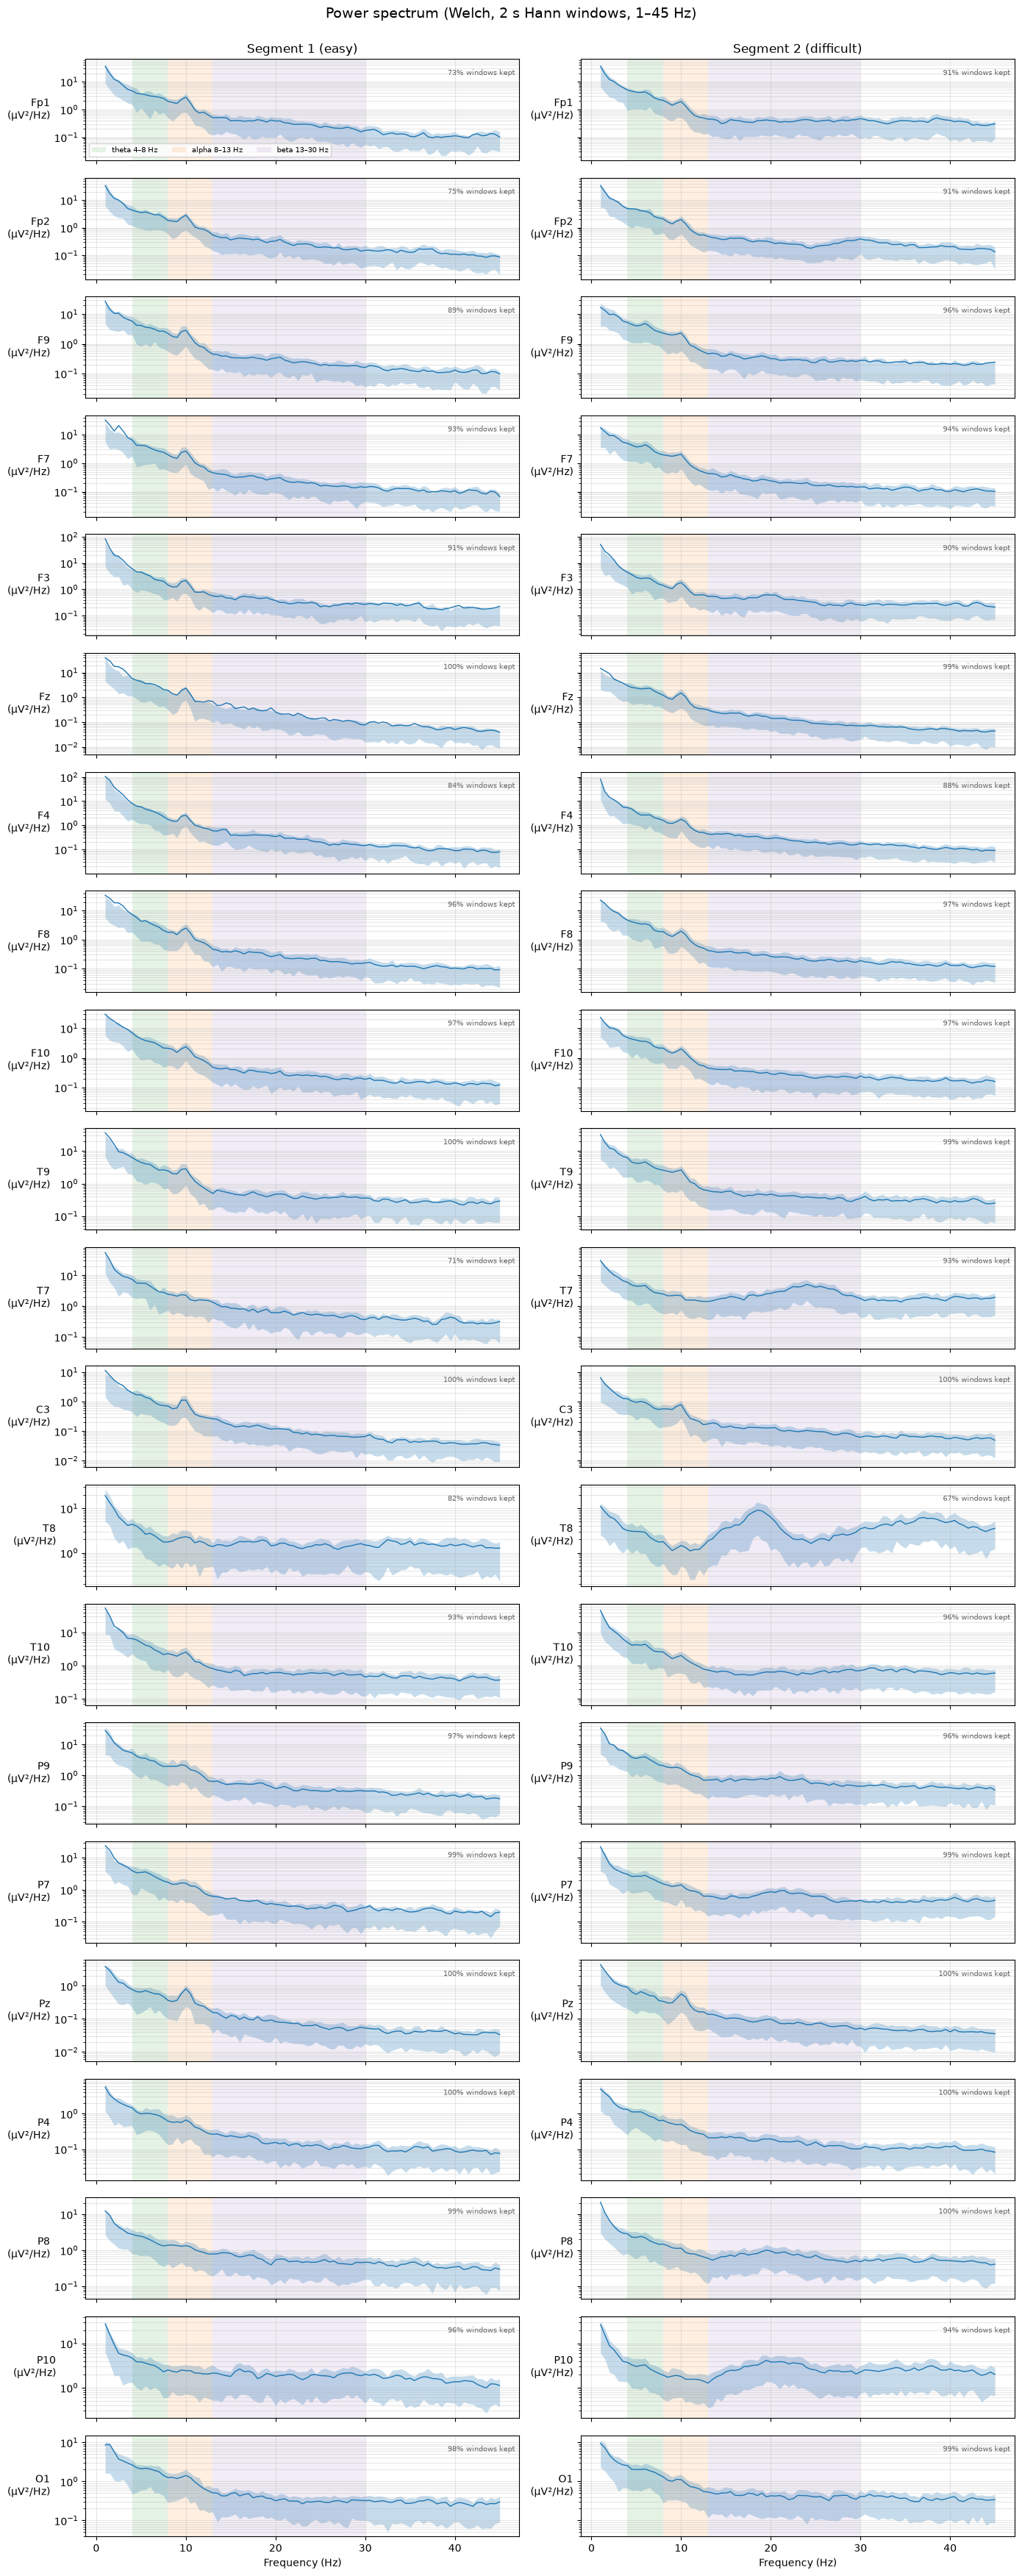

In [11]:
def plot_spectra(spectra, title):
    n = len(FFT_CHANNELS)
    fig, axes = plt.subplots(n, 2, figsize=(14, 1.7 * n), sharex=True, sharey="row", squeeze=False)
    for col, (psd, f, _, keep) in enumerate(spectra):
        mean = np.nanmean(psd, axis=0)
        lo, hi = np.nanpercentile(psd, [25, 75], axis=0)
        for row, ch in enumerate(FFT_CHANNELS):
            ax = axes[row, col]
            for name, (b0, b1) in BANDS.items():
                ax.axvspan(b0, b1, color=BAND_COLORS[name], alpha=0.12, lw=0,
                           label=f"{name} {b0}–{b1} Hz" if row == 0 else None)
            ax.fill_between(f, lo[row], hi[row], color="C0", alpha=0.25, lw=0)
            ax.plot(f, mean[row], color="C0", lw=1)
            ax.set_yscale("log")
            ax.set_ylabel(f"{ch}\n(µV²/Hz)", rotation=0, ha="right", va="center")
            ax.text(0.99, 0.9, f"{100 * keep[row]:.0f}% windows kept", transform=ax.transAxes,
                    ha="right", va="top", fontsize=7, color="red" if keep[row] < MIN_KEEP else "0.4")
            ax.grid(alpha=0.3, which="both")
        axes[0, col].set_title(f"Segment {col + 1} ({'easy' if col == 0 else 'difficult'})")
        axes[-1, col].set_xlabel("Frequency (Hz)")
    axes[0, 0].legend(loc="lower left", fontsize=7, ncol=3)
    fig.suptitle(title, fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    plt.show()


plot_spectra(spectra, "Power spectrum (Welch, 2 s Hann windows, 1–45 Hz)")

### 7b. Relative band power per channel, segment 1 vs segment 2

Each bar is a band's share of all 4–40 Hz power, averaged over the clean windows.

**Why this plot:** it shows across the whole head whether theta rises and alpha falls in the difficult task, which is the pattern expected under higher mental workload.

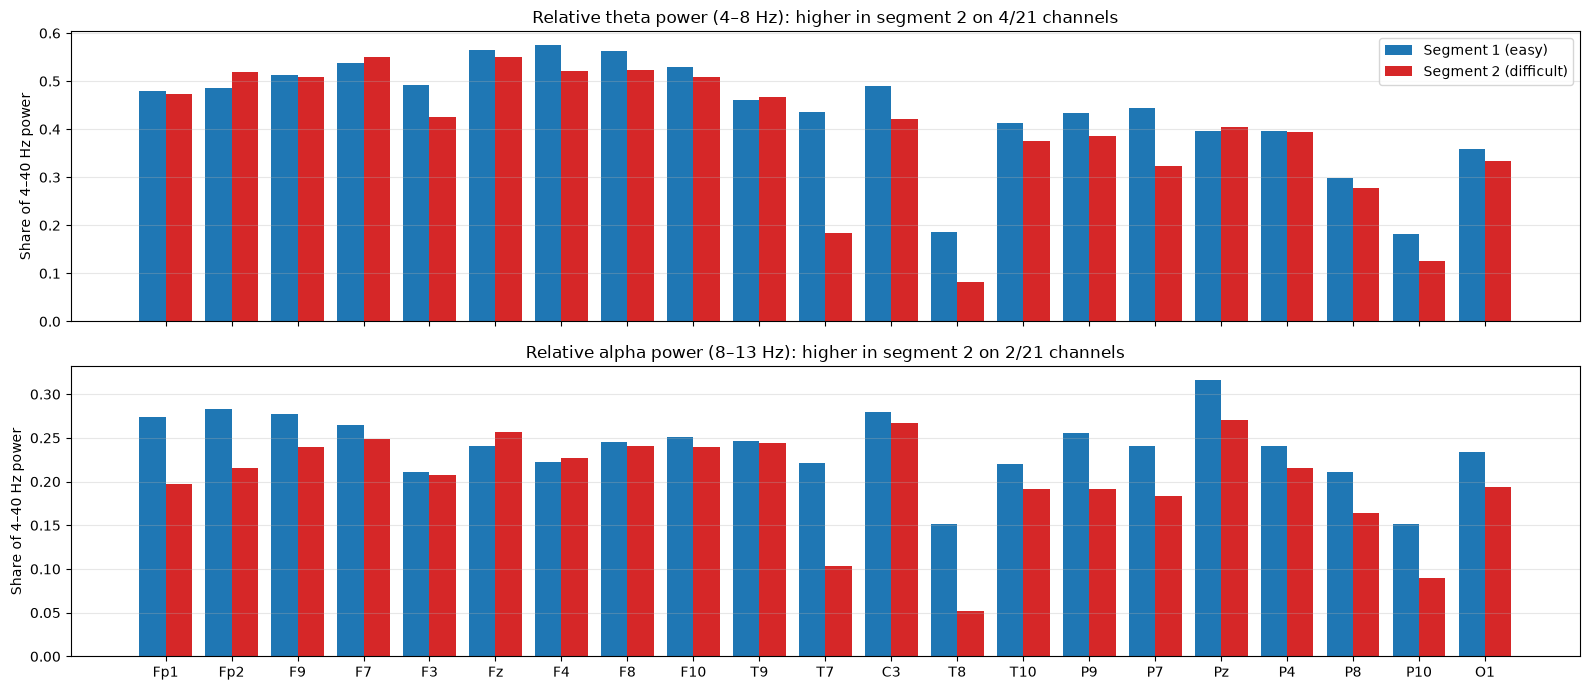

channel     abs θ seg1    abs θ seg2    rel θ seg1    rel θ seg2    rel α seg1    rel α seg2
Fp1             13.397        15.250         0.479         0.474         0.274         0.198
Fp2             13.515        15.412         0.486         0.519         0.283         0.216
F9              14.858        16.024         0.513         0.509         0.278         0.240
F7              15.267        14.862         0.538         0.551         0.265         0.249
F3              14.368        11.130         0.492         0.424         0.211         0.208
Fz              15.171         8.977         0.565         0.550         0.240         0.256
F4              18.869        12.730         0.575         0.521         0.223         0.227
F8              16.850        13.413         0.562         0.524         0.245         0.241
F10             16.017        14.040         0.530         0.508         0.251         0.240
T9              16.193        16.823         0.462         0.468      

In [12]:
abs_power = {b: [np.nanmean(band_power(p, freqs, rng), axis=0) for p, *_ in spectra] for b, rng in BANDS.items()}
total_power = [np.nanmean(band_power(p, freqs, TOTAL), axis=0) for p, *_ in spectra]
rel_power = {b: [abs_power[b][i] / total_power[i] for i in range(2)] for b in BANDS}

x = np.arange(len(FFT_CHANNELS))
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
for ax, band in zip(axes, ["theta", "alpha"]):
    ax.bar(x - 0.2, rel_power[band][0], 0.4, label="Segment 1 (easy)", color="C0")
    ax.bar(x + 0.2, rel_power[band][1], 0.4, label="Segment 2 (difficult)", color="C3")
    up = int((rel_power[band][1] > rel_power[band][0]).sum())
    ax.set_title(f"Relative {band} power ({BANDS[band][0]}–{BANDS[band][1]} Hz): "
                 f"higher in segment 2 on {up}/{len(x)} channels")
    ax.set_ylabel("Share of 4–40 Hz power")
    ax.grid(axis="y", alpha=0.3)
axes[0].legend()
axes[-1].set_xticks(x, FFT_CHANNELS)
fig.tight_layout()
plt.show()

print(f"{'channel':8}" + "".join(f"{h:>14}" for h in ["abs θ seg1", "abs θ seg2", "rel θ seg1", "rel θ seg2", "rel α seg1", "rel α seg2"]))
for k, ch in enumerate(FFT_CHANNELS):
    vals = [abs_power["theta"][0][k], abs_power["theta"][1][k], rel_power["theta"][0][k],
            rel_power["theta"][1][k], rel_power["alpha"][0][k], rel_power["alpha"][1][k]]
    print(f"{ch:8}" + "".join(f"{v:14.3f}" for v in vals))

### 7c. Testing the hypothesis at Fz

Theta at Fz is the standard workload marker. This compares each segment's windows using
**non-overlapping** windows only, since overlapping windows share data and would make the test
look more certain than it is. The p-value is from a one-sided Mann–Whitney U test (is segment 2 higher?), but it is
**descriptive only**: windows cut from one continuous recording are not independent samples,
so treating them as such (pseudoreplication) makes any difference look more certain than it
is. A real significance test needs several separate blocks per condition, or several people.
The third panel is a simple combined index, Fz theta / Pz alpha. It rises when frontal theta
rises *or* parietal alpha falls, the two changes seen together as workload increases
([Smith, Gevins et al., 2001](https://swov.nl/en/publicatie/monitoring-task-loading-multivariate-eeg-measures-during-complex-forms-human-computer)).

**Why this plot:** it compares Fz theta (the main workload marker) between the two tasks window by window and shows how much the windows vary, not just the averages.

Absolute theta at Fz (µV²)   segment 1 median 8.482 (n=74), segment 2 median 7.456 (n=100), descriptive p = 0.97
Relative theta at Fz         segment 1 median 0.541 (n=74), segment 2 median 0.516 (n=100), descriptive p = 0.73
Fz theta / Pz alpha          segment 1 median 5.117 (n=74), segment 2 median 5.312 (n=100), descriptive p = 0.51


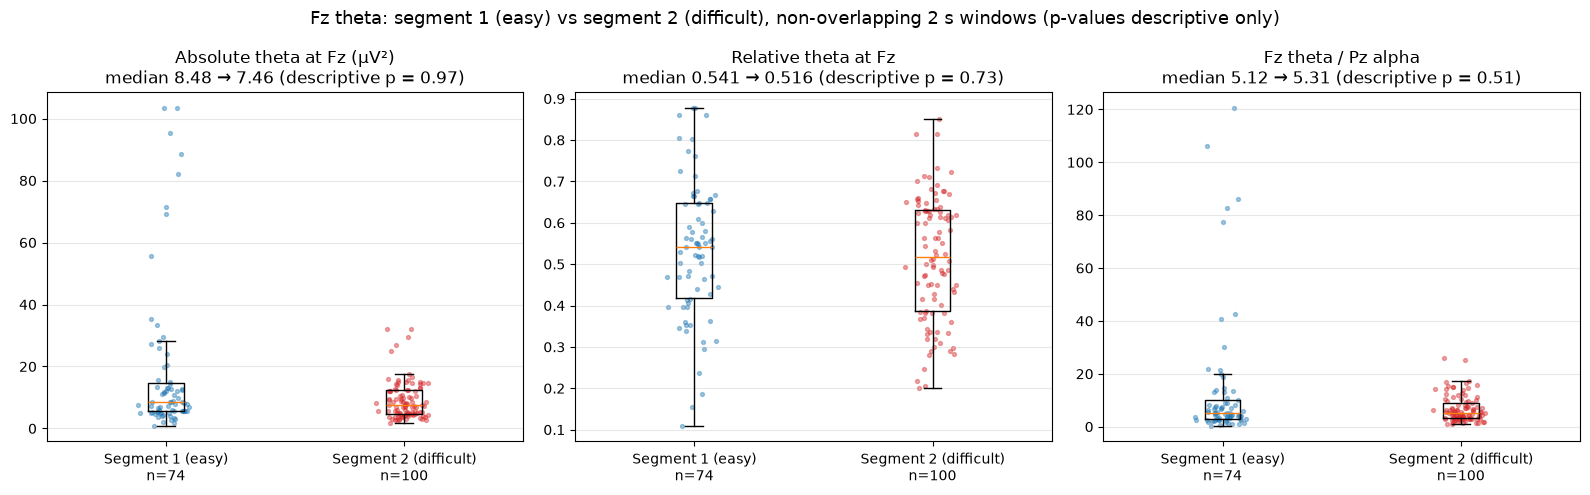

In [13]:
fz, pz = FFT_CHANNELS.index("Fz"), FFT_CHANNELS.index("Pz")
measures = {"Absolute theta at Fz (µV²)": [], "Relative theta at Fz": [], "Fz theta / Pz alpha": []}
for seg in session.segments:
    psd, f, _, _ = window_spectra(seg, overlap=0.0)
    theta_fz = band_power(psd, f, BANDS["theta"])[:, fz]
    values = [theta_fz,
              theta_fz / band_power(psd, f, TOTAL)[:, fz],
              theta_fz / band_power(psd, f, BANDS["alpha"])[:, pz]]
    for key, v in zip(measures, values):
        measures[key].append(v[~np.isnan(v)])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (label, (s1, s2)) in zip(axes, measures.items()):
    p = mannwhitneyu(s2, s1, alternative="greater").pvalue
    ax.boxplot([s1, s2], showfliers=False)
    for i, s in enumerate([s1, s2], start=1):
        ax.scatter(np.random.default_rng(0).normal(i, 0.05, len(s)), s, s=8, alpha=0.4,
                   color="C0" if i == 1 else "C3")
    ax.set_xticks([1, 2], [f"Segment 1 (easy)\nn={len(s1)}", f"Segment 2 (difficult)\nn={len(s2)}"])
    ax.set_title(f"{label}\nmedian {np.median(s1):.3g} → {np.median(s2):.3g} (descriptive p = {p:.2g})")
    ax.grid(axis="y", alpha=0.3)
    print(f"{label:28} segment 1 median {np.median(s1):.3f} (n={len(s1)}), "
          f"segment 2 median {np.median(s2):.3f} (n={len(s2)}), descriptive p = {p:.2g}")
fig.suptitle("Fz theta: segment 1 (easy) vs segment 2 (difficult), non-overlapping 2 s windows (p-values descriptive only)", fontsize=13)
fig.tight_layout()
plt.show()

### 7d. Results from relative power (see section 8 for the cleaned analysis)

**Using relative power, frontal theta did not rise in the difficult task, but parietal alpha
did fall. Section 8 revisits this on ICA-cleaned data with the 1/f background removed,
which changes the theta result.**

All p-values below are descriptive only (windows from one recording are not independent).

| Measure | Segment 1 (easy) | Segment 2 (difficult) | Supports hypothesis? |
|---|---|---|---|
| Relative theta at Fz (share of 4–40 Hz, median per window) | 0.541 | 0.516 | **No** (descriptive p = 0.73) |
| Absolute theta at Fz (median, µV²) | 8.48 | 7.46 | No (descriptive p = 0.97) |
| Fz theta / Pz alpha (median) | 5.12 | 5.31 | No difference (descriptive p = 0.51) |
| Relative theta higher in segment 2 | | | Only 4 of 21 channels |
| **Posterior alpha** (P9, P7, Pz, P4, P8, P10, O1) | 5.40 µV² | 4.67 µV² | **Yes**: lower on all 7 channels; absolute power descriptive p = 0.0005 |

**Correction to an earlier version of this analysis:** relative power was first computed as
a share of 1–40 Hz, which made Fz theta look higher in segment 2 (0.198 → 0.240, descriptive p = 0.021).
That increase came entirely from **delta (1–4 Hz) dropping** in segment 2 (share 0.58 → 0.48),
which pushes every other band's share up. With delta excluded, theta does not rise. Delta here
is most likely slow drift and electrode settling after the impedance re-check, not brain
activity, so it's now left out of the total.

How to read this:
- **Lower parietal alpha in the difficult task is a genuine change:** it drops in absolute
  power too, while beta on the same channels rises (8.7 → 13.0 µV²), so it isn't just all
  power shrinking with electrode contact. Alpha falling over parietal areas as mental demand
  rises is the expected workload pattern ([Gevins et al., 1997](https://pubmed.ncbi.nlm.nih.gov/9177767/)).
- **Frontal theta, the main workload marker in the hypothesis, shows no increase.** Either the
  difficulty difference wasn't large enough to change it, or 2.5 minutes per task is too
  little data to detect it in one person.

**Why this can't confirm the hypothesis:**
1. **Order confound:** the difficult task was always second, and alpha also changes with time on task.
2. **One person, one session.**
3. **Segment 2 has more 20–45 Hz power on Fp1/Fp2/F9** (Fp1 roughly doubles, 4.5 → 9.5 µV²;
   see 7a), which suggests more muscle tension. That can come with harder tasks, but it is not brain activity.

**Next steps to make this conclusive:** counterbalance the task order (difficult first in some
sessions), record more people/sessions, and keep a short rest baseline before each task.

## 8. Cleaned analysis: ICA + theta/alpha above the 1/f background

Two problems limit section 7: eye blinks and muscle activity are still in the data (only
extreme windows were dropped), and relative power is thrown off by changes across the whole
spectrum, such as more muscle activity or drift (the delta problem in 7d). This section
addresses both.

**1. ICA with ICLabel.** ICA splits the EEG into independent components; ICLabel, a
classifier trained on thousands of labelled components, rates each one as brain, eye, muscle,
heart, line noise, channel noise or other. Components rated eye, muscle, heart, line or
channel noise with probability ≥ 0.7 are removed. One ICA is fitted on both segments
together, so both are cleaned the same way. ICLabel requires 1–100 Hz filtered,
average-referenced data, so the cleaned data is average-referenced.

**2. FOOOF (spectral parameterization)** ([Donoghue et al., 2020](https://doi.org/10.1038/s41593-020-00744-x)).
An EEG spectrum is a sloping 1/f background plus oscillation peaks on top. FOOOF fits the
background, and theta and alpha are measured as power **above** it, in dB. Muscle activity
mostly flattens the background (lower exponent) rather than adding a theta or alpha peak, so
this keeps broadband shifts from looking like band changes.

**Statistics:** medians and their difference are the result. p-values are descriptive only
(windows from one recording are not independent samples).

In [14]:
from processing.cleaning import prepare, ica_clean
from processing.analysis import (
    fit_fooof, periodic_power_db, periodic_workload_comparison, plot_fooof_fits, plot_periodic_bars,
    window_spectra as clean_window_spectra, BANDS as CLEAN_BANDS,
)

prepared = [prepare(seg, BAD_CHANNELS) for seg in session.segments]
cleaned, ica_report, ica = ica_clean(prepared)
print(f"ICA: {len(ica_report)} components, {int(ica_report.removed.sum())} removed "
      f"(artifact label with probability ≥ 0.7)")
ica_report

ICA: 20 components, 6 removed (artifact label with probability ≥ 0.7)


,component,label,probability,removed
0,IC00,eye blink,0.99,True
1,IC01,other,0.65,False
2,IC02,muscle artifact,0.56,False
3,IC03,other,0.96,False
4,IC04,eye blink,0.45,False
5,IC05,eye blink,1.00,True
6,IC06,other,0.56,False
7,IC07,muscle artifact,1.00,True
8,IC08,muscle artifact,0.69,False
9,IC09,eye blink,0.65,False


### 8a. Removed components

**Why this plot:** it lets you check that the removed components look like artifacts (blinks concentrate at Fp1/Fp2; muscle sits at the edges of the cap), not brain activity.

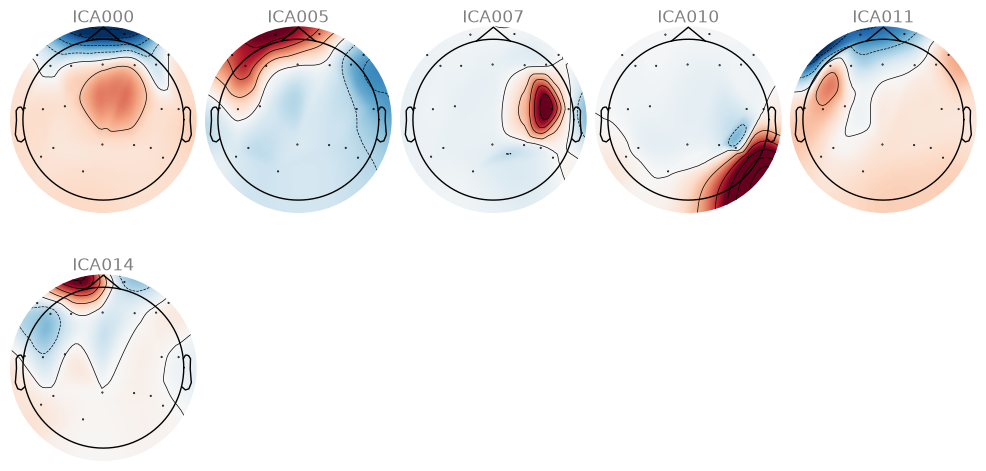

In [15]:
ica.plot_components(picks=ica.exclude, title="Components removed by ICLabel", show=False)
plt.show()

### 8b. Spectra with the 1/f background

**Why this plot:** it shows the 1/f background FOOOF fitted for each task and what remains above it, so you can see whether a band difference is a real peak or just a shift of the whole spectrum.

Segment 1 (easy): median 100% of windows kept per channel (Fz 100%)
Segment 2 (difficult): median 99% of windows kept per channel (Fz 100%)


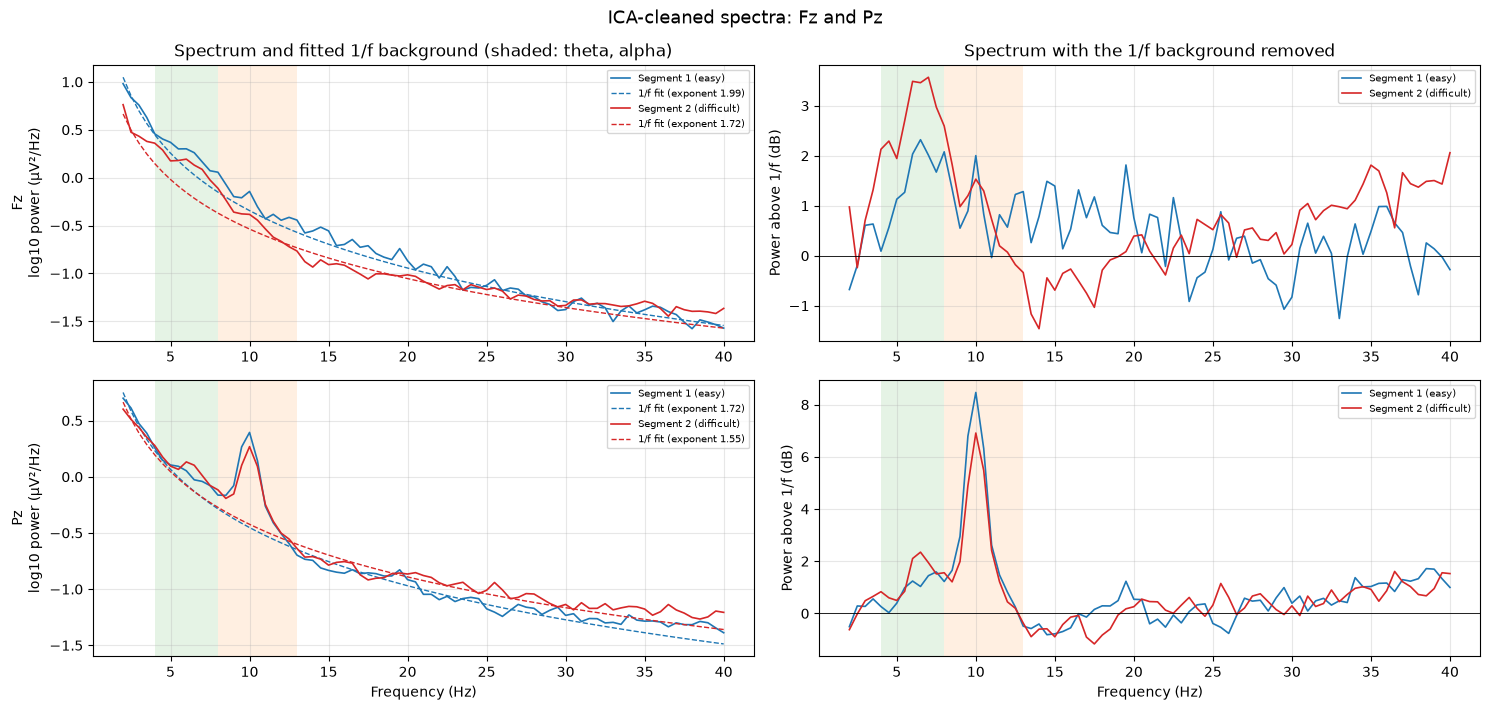

In [16]:
CLEAN_LABELS = ["Segment 1 (easy)", "Segment 2 (difficult)"]
clean_spectra = [clean_window_spectra(seg) for seg in cleaned]
for label, (_, _, chs, keep) in zip(CLEAN_LABELS, clean_spectra):
    print(f"{label}: median {100 * np.median(keep):.0f}% of windows kept per channel (Fz {100 * keep[chs.index('Fz')]:.0f}%)")
_ = plot_fooof_fits(clean_spectra, CLEAN_LABELS, "ICA-cleaned spectra: Fz and Pz", channels=("Fz", "Pz"))

### 8c. Theta and alpha above 1/f, per channel

**Why this plot:** it shows across the whole head whether theta rises and alpha falls in the difficult task once the 1/f background is removed, and the exponent row shows how much the background itself changed (a sign of muscle activity).

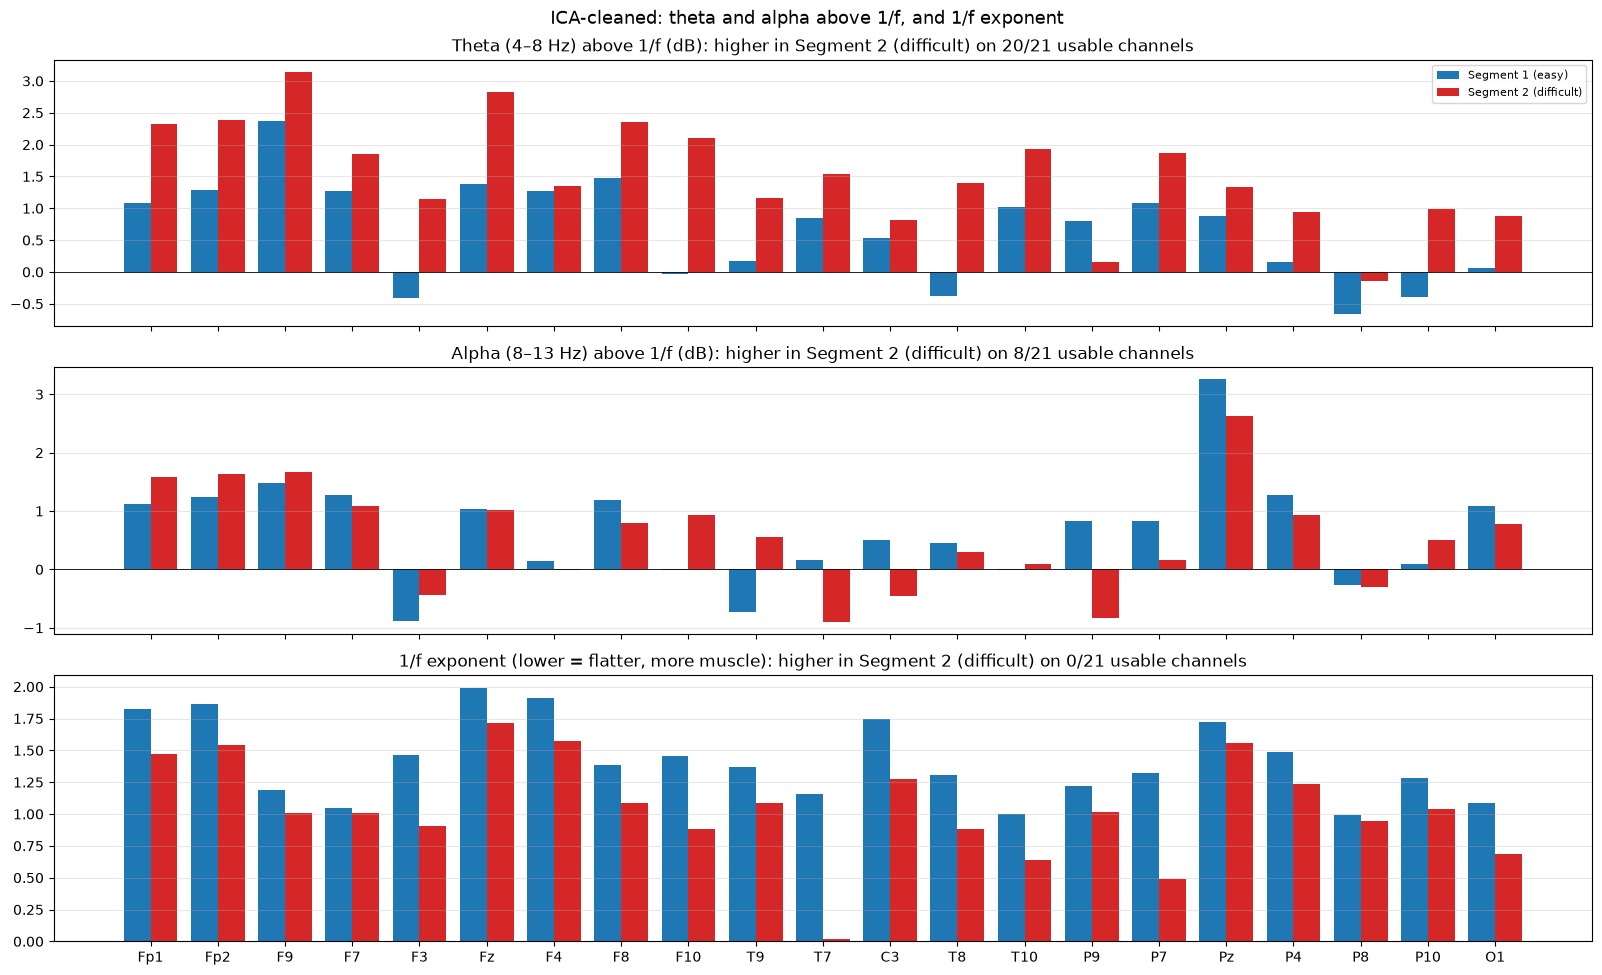

,Theta (4–8 Hz) above 1/f (dB) [Segment 1 (easy)],Theta (4–8 Hz) above 1/f (dB) [Segment 2 (difficult)],Alpha (8–13 Hz) above 1/f (dB) [Segment 1 (easy)],Alpha (8–13 Hz) above 1/f (dB) [Segment 2 (difficult)],"1/f exponent (lower = flatter, more muscle) [Segment 1 (easy)]","1/f exponent (lower = flatter, more muscle) [Segment 2 (difficult)]"
Fp1,1.08,2.32,1.13,1.59,1.82,1.47
Fp2,1.29,2.39,1.25,1.64,1.87,1.54
F9,2.37,3.14,1.48,1.68,1.19,1.01
F7,1.28,1.86,1.28,1.08,1.05,1.01
F3,-0.41,1.15,-0.89,-0.45,1.46,0.90
Fz,1.39,2.82,1.03,1.02,1.99,1.72
F4,1.27,1.35,0.14,-0.00,1.91,1.57
F8,1.48,2.35,1.19,0.80,1.39,1.08
F10,-0.03,2.10,-0.01,0.92,1.45,0.88
T9,0.17,1.16,-0.74,0.55,1.37,1.08


In [17]:
periodic_table = plot_periodic_bars(clean_spectra, CLEAN_LABELS, "ICA-cleaned: theta and alpha above 1/f, and 1/f exponent")
periodic_table

### 8d. Fz theta and Pz alpha, window by window

**Why this plot:** it compares the two workload markers between tasks on every non-overlapping 2 s window, showing the spread and not just one averaged number.

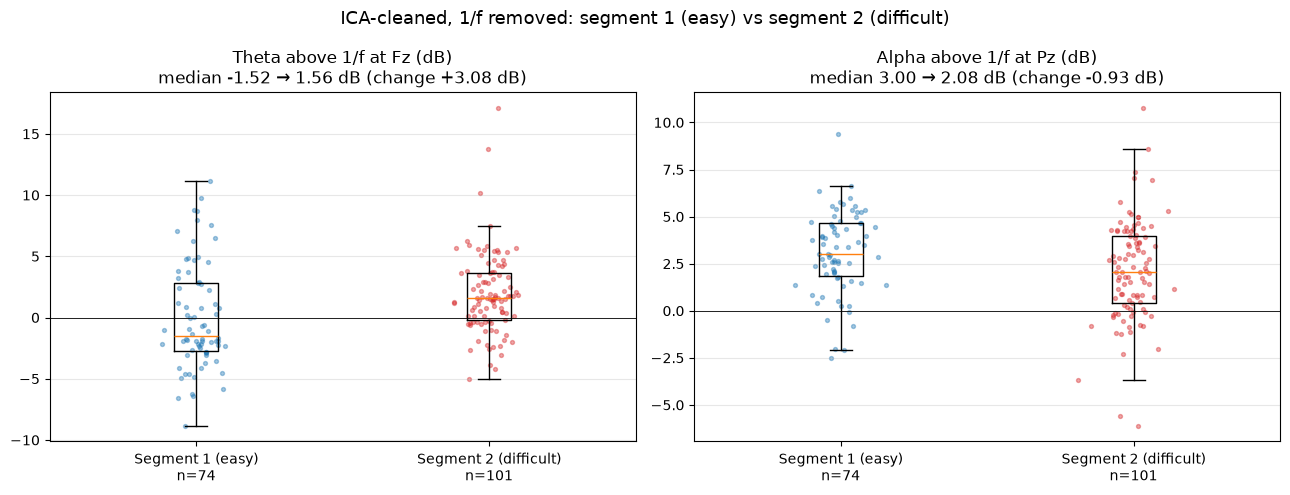

,Segment 1 (easy),Segment 2 (difficult),change_dB,descriptive_p_higher,descriptive_p_lower,n
measure,,,,,,
Theta above 1/f at Fz (dB),-1.52,1.56,3.08,0.000056,1.0000,74 / 101
Alpha above 1/f at Pz (dB),3.00,2.08,-0.93,1.000000,0.0029,74 / 101


In [18]:
clean_spectra_nonoverlap = [clean_window_spectra(seg, overlap=0.0) for seg in cleaned]
periodic_workload_comparison(clean_spectra_nonoverlap, CLEAN_LABELS,
                             "ICA-cleaned, 1/f removed: segment 1 (easy) vs segment 2 (difficult)")

### 8e. Results: does the cleaned data support the hypothesis?

**Yes, in direction: after ICA and with the 1/f background removed, frontal theta is higher
and parietal alpha lower in the difficult task, which is the expected workload pattern. But it
cannot be separated from extra muscle activity and from task order in this recording.**

| Measure (ICA-cleaned, above 1/f) | Segment 1 (easy) | Segment 2 (difficult) | Change |
|---|---|---|---|
| Theta at Fz, averaged spectrum | +1.39 dB | +2.82 dB | **+1.4 dB** |
| Theta at Fz, median of 2 s windows | −1.52 dB | +1.56 dB | **+3.1 dB** (descriptive p = 0.00006) |
| Alpha at Pz, averaged spectrum | +3.25 dB | +2.63 dB | **−0.6 dB** |
| Alpha at Pz, median of 2 s windows | +3.00 dB | +2.08 dB | **−0.9 dB** (descriptive p = 0.003) |
| Channels with higher theta above 1/f in segment 2 | | | 20 of 21 |
| Channels with a lower (flatter) 1/f exponent in segment 2 | | | **21 of 21** |

- **ICA removed 6 of 20 components:** 4 eye (blinks and eye movements, concentrated at Fp1/Fp2)
  and 2 muscle (small hotspots at the edge of the cap). Less certain muscle components (ICLabel
  probability 0.56 and 0.69) were kept.
- **The result holds across fitting choices:** with frequency ranges 1–40, 2–30, 2–40, 3–40,
  2–45 Hz and a "knee" background model, Fz theta rises by 1.2–4.7 dB and Pz alpha falls by
  0.6–0.9 dB in every case.
- **Why section 7 found no theta increase:** segment 2's whole spectrum is flatter (lower
  1/f exponent on every channel). At Fz its raw 4–8 Hz power is actually lower than segment 1's,
  but the background drops even more, leaving a larger theta peak on top. Relative power can't
  separate these two changes; FOOOF can.

**What still limits this conclusion:**
1. **Muscle activity:** a flatter spectrum on every channel means more high-frequency (muscle)
   activity in the difficult task. FOOOF separates it from the theta peak, but the separation
   depends on modelling the background correctly, and more muscle tension is itself
   confounded with difficulty.
2. **Order confound:** the difficult task was always second.
3. **One person, one session:** the p-values are descriptive only. Real inference needs
   several blocks per condition or several people, plus a rest baseline and subjective effort
   ratings (e.g. NASA-TLX) to check that the EEG measure tracks effort at all.